# Kelvin event locations in wavenumber–frequency space

**Agent-authored exploratory analysis.** One NOAA record and 59 CMIP6 model/experiment records (34 Historical, 25 AMIP), each with one member, over 1990–2010. Every record has its own joint histogram. Figures are embedded in this notebook; no standalone figure files are written.

**Question.** Where do detected Kelvin events lie within the project's wavenumber–frequency filter box, and how much do individual model distributions vary?

## Inputs and plotted quantities

The derived input tables come from `scripts/codex_kelvin_komega/extract.py`, which reads the full **1.5σ active-component** Kelvin event catalogs through `data/` and excludes pilots. A detected candidate has a Hilbert envelope above the event threshold; the separate 1% amplitude-significance test is **not** applied here.

The primary axes use the standard spectral coordinates: fitted global zonal wavenumber $K$ (cycles around Earth, positive/eastward for Kelvin) and fitted frequency $f$ (cycles per day). Top and right axes give the dimensional quantities requested: $k=K/R$ in rad m$^{-1}$ and $\omega=2\pi f/86400$ in rad s$^{-1}$, with $R=6{,}371{,}008$ m. Fits are continuous, so $K$ need not be an integer Fourier wavenumber. The common wavenumber bins are centered on integer $K=1,\ldots,15$ (edges 0.5–15.5); frequency bins have width 0.02 cycles/day from 0.07 to 0.41. Each bin contains a **percentage of that record's selected events**; white bins have zero events. Color limits are identical across NOAA and all models *within each selection*.

The two selections are (1) every successfully fitted candidate and (2) `keep_for_histogram`, the established fit-quality screen used for the equivalent-depth distributions. Neither selection requires individual amplitude significance.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import numpy as np
import pandas as pd
from IPython.display import display

from src.paths import DATA_DIR

INPUT = DATA_DIR / "wave_significance/codex_kelvin_komega"
EVENTS_PATH = INPUT / "kelvin_event_fits.csv.gz"
INDEX_PATH = INPUT / "kelvin_catalog_index.csv"
if not EVENTS_PATH.is_file() or not INDEX_PATH.is_file():
    raise FileNotFoundError("Run scripts/codex_kelvin_komega/extract.py on Levante and copy its two compact CSVs here")
events = pd.read_csv(EVENTS_PATH)
index = pd.read_csv(INDEX_PATH)
IDENTITY = ["model", "experiment", "member"]
if (len(index) != 60 or index[IDENTITY].duplicated().any()
        or index.experiment.value_counts().to_dict() != {"historical": 34, "amip": 25, "observations": 1}
        or len(events) != index.candidates.sum()
        or events[IDENTITY + ["event_id"]].duplicated().any()):
    raise RuntimeError("Kelvin extraction has incomplete or duplicated records")
actual = events.groupby(IDENTITY).agg(candidates=("event_id", "size"),
                                      successful_fits=("fit_success", "sum"),
                                      quality_screened=("keep_for_histogram", "sum")).reset_index()
if not actual.sort_values(IDENTITY).reset_index(drop=True).equals(
        index[IDENTITY + ["candidates", "successful_fits", "quality_screened"]]
        .sort_values(IDENTITY).reset_index(drop=True)):
    raise RuntimeError("Extracted event counts do not match the catalog audit")
records = pd.concat((index.loc[index.experiment.eq("observations")],
                     index.loc[index.experiment.eq("historical")].sort_values("model"),
                     index.loc[index.experiment.eq("amip")].sort_values("model")), ignore_index=True)
print("Loaded", len(events), "event candidates from", len(records), "full catalogs")
display(index.groupby("experiment")[["candidates", "successful_fits", "quality_screened"]].agg(["sum", "min", "max"]))

Loaded 170639 event candidates from 60 full catalogs


candidates             successful_fits              \
                    sum   min   max             sum   min   max   
experiment                                                        
amip              71062  2363  3272           71062  2363  3272   
historical        96680  2468  3310           96679  2468  3310   
observations       2897  2897  2897            2897  2897  2897   

             quality_screened            
                          sum  min  max  
experiment                               
amip                    18224  572  824  
historical              24753  564  874  
observations              767  767  767

In [2]:
K_EDGES = np.arange(0.5, 16.0, 1.0)
F_EDGES = np.arange(0.07, 0.4101, 0.02)
EARTH_RADIUS_M = 6_371_008.0
histograms = {}
color_limits = {}
for selection in ("fit_success", "keep_for_histogram"):
    by_record = {}
    for identity, frame in events.groupby(IDENTITY, sort=False):
        selected = frame.loc[frame[selection].fillna(False)]
        if selected.empty:
            raise RuntimeError(f"No {selection} events for {identity}")
        counts, _, _ = np.histogram2d(selected.K_global, selected.frequency_cpd,
                                       bins=(K_EDGES, F_EDGES))
        percent = 100 * counts / len(selected)
        if not np.isclose(percent.sum(), 100):
            raise RuntimeError(f"Fitted coordinates outside common bins: {identity}/{selection}")
        by_record[identity] = (percent, len(selected))
    histograms[selection] = by_record
    color_limits[selection] = max(percent.max() for percent, _ in by_record.values())
print("Common color maxima (% per bin):", {key: round(value, 2) for key, value in color_limits.items()})

def plot_records(selection, experiment):
    """Display one single-panel joint histogram for each record in an experiment."""
    cmap = plt.get_cmap("magma").copy()
    cmap.set_bad("white")
    norm = Normalize(vmin=0, vmax=color_limits[selection])
    for row in records.loc[records.experiment.eq(experiment)].itertuples(index=False):
        percent, n = histograms[selection][(row.model, row.experiment, row.member)]
        fig, ax = plt.subplots(figsize=(7.2, 4.8), dpi=95, layout="constrained")
        mesh = ax.pcolormesh(K_EDGES, F_EDGES, np.ma.masked_equal(percent.T, 0),
                             cmap=cmap, norm=norm, shading="flat")
        ax.set(xlim=(0.5, 15.5), ylim=(0.07, 0.41),
               xlabel="Fitted global zonal wavenumber K (cycles/circumference)",
               ylabel="Fitted frequency f (cycles/day)")
        ax.set_xticks(np.arange(1, 16, 2))
        ax.set_yticks([0.07, 0.1, 0.2, 0.3, 0.4])
        top = ax.secondary_xaxis("top", functions=(
            lambda K: K / EARTH_RADIUS_M * 1e6,
            lambda k_scaled: k_scaled * 1e-6 * EARTH_RADIUS_M))
        top.set_xlabel(r"$k$ ($10^{-6}$ rad m$^{-1}$)")
        right = ax.secondary_yaxis("right", functions=(
            lambda f: 2 * np.pi * f / 86400 * 1e5,
            lambda omega_scaled: omega_scaled * 1e-5 * 86400 / (2 * np.pi)))
        right.set_ylabel(r"$\omega$ ($10^{-5}$ rad s$^{-1}$)")
        fig.colorbar(mesh, ax=ax, label="Percent of selected events per bin", pad=0.13)
        label = "all successful fits" if selection == "fit_success" else "quality-screened fits"
        record = "NOAA OLR" if row.experiment == "observations" else f"{row.model} ({row.experiment}, {row.member})"
        fig.suptitle(f"{record} — Kelvin {label} (n={n})", fontsize=9)
        display(fig)
        plt.close(fig)

Common color maxima (% per bin): {'fit_success': np.float64(5.41), 'keep_for_histogram': np.float64(9.15)}


## All successfully fitted candidates

These panels show the detector population with only unsuccessful fits removed. Fit positions near the filter-box boundaries may be influenced by the search bounds or poor sinusoid coherence. The common color limit for this section is calculated from all 60 records.

### NOAA observations

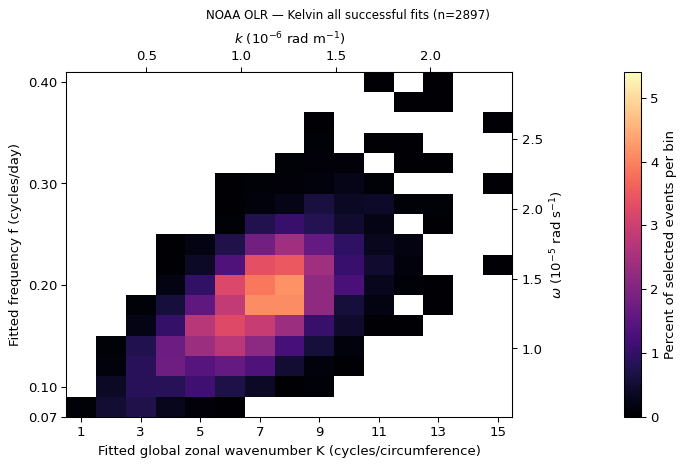

In [3]:
plot_records("fit_success", "observations")

### Historical models (34 records)

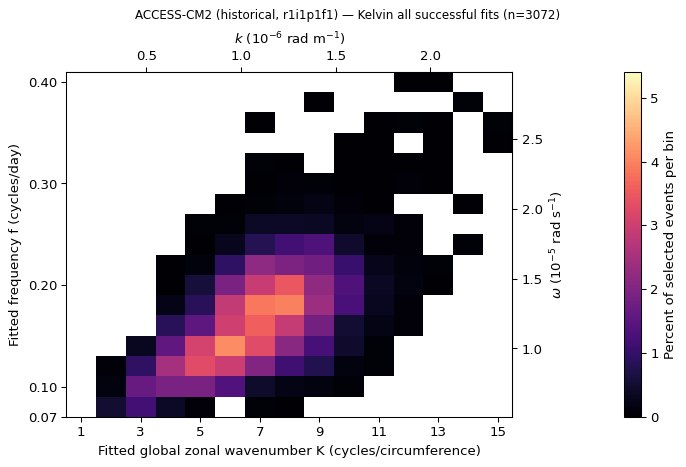

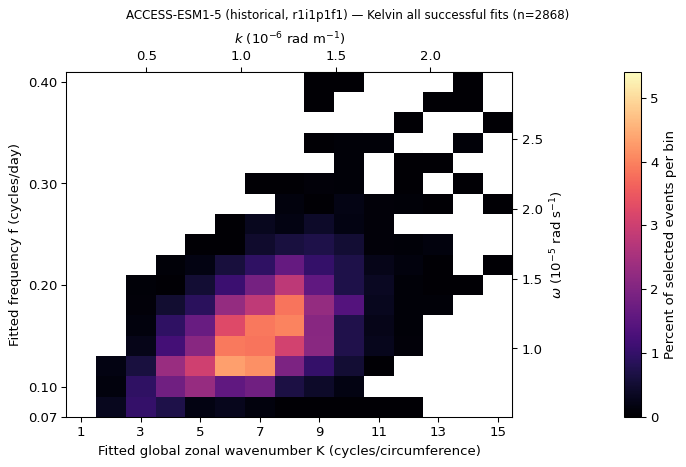

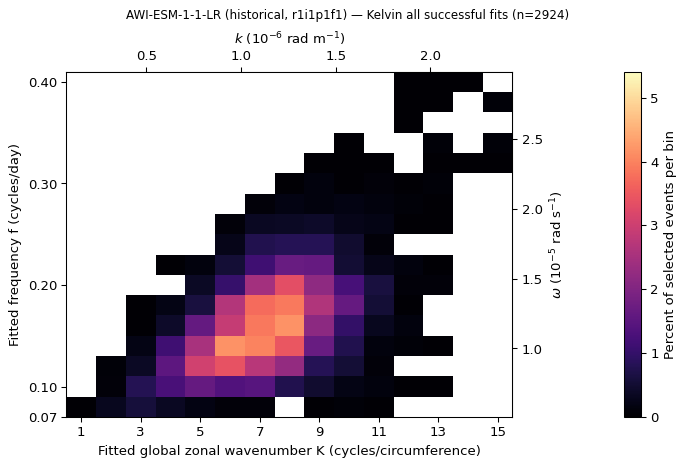

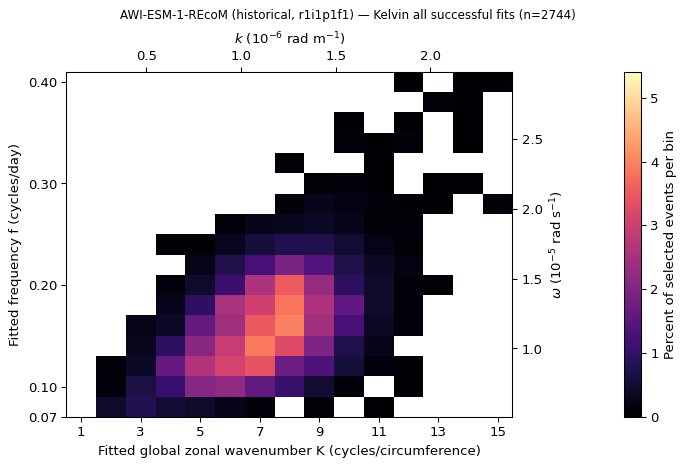

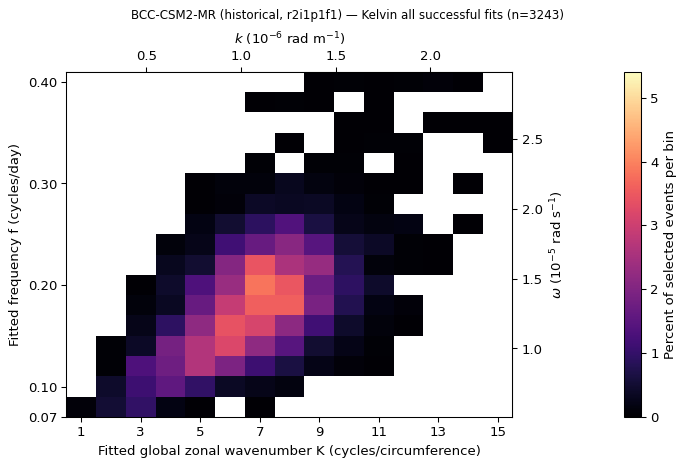

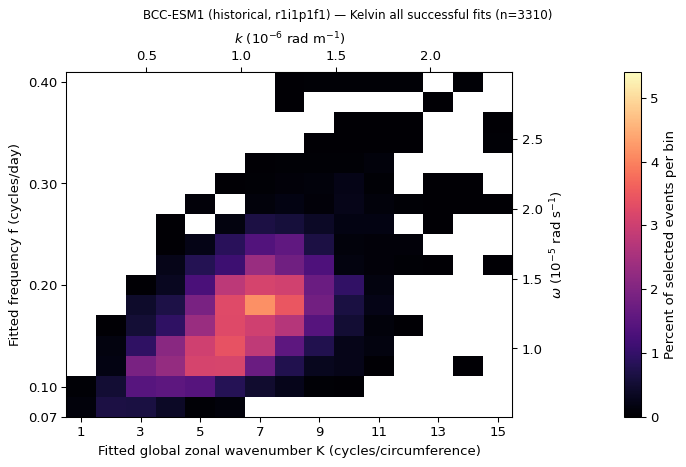

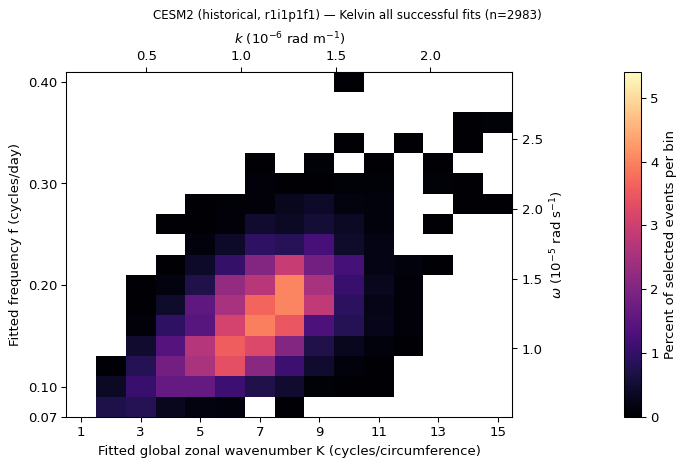

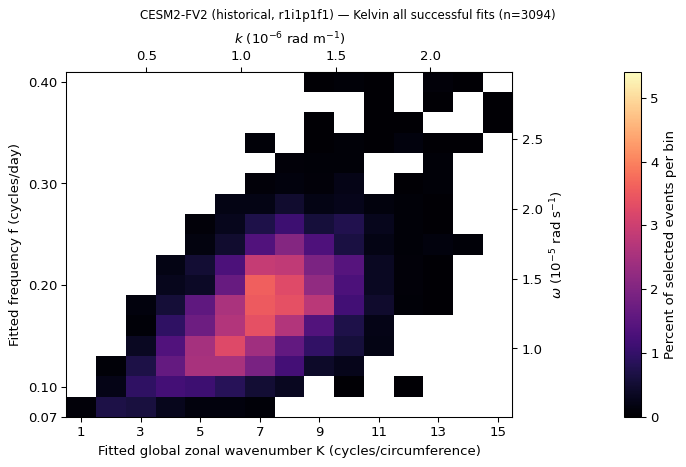

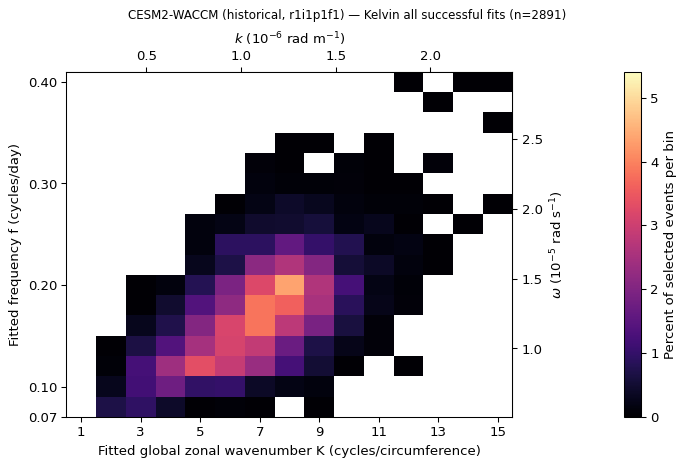

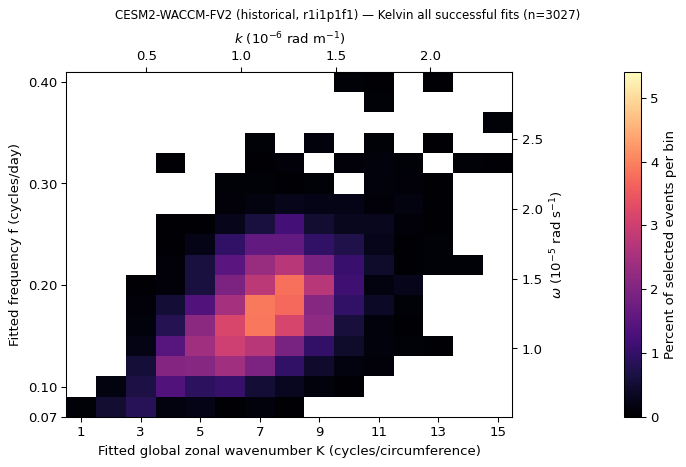

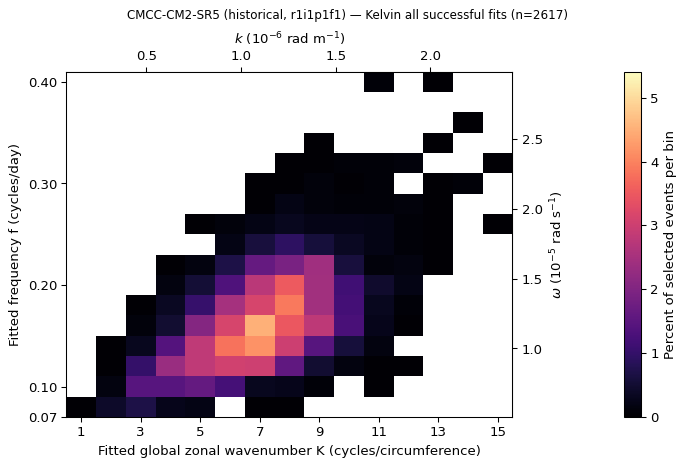

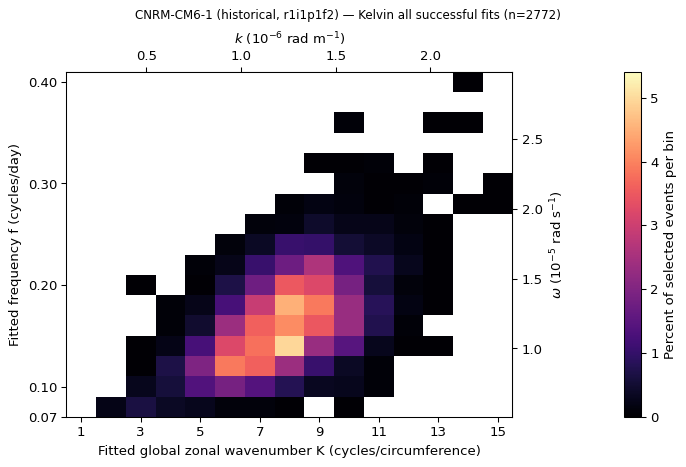

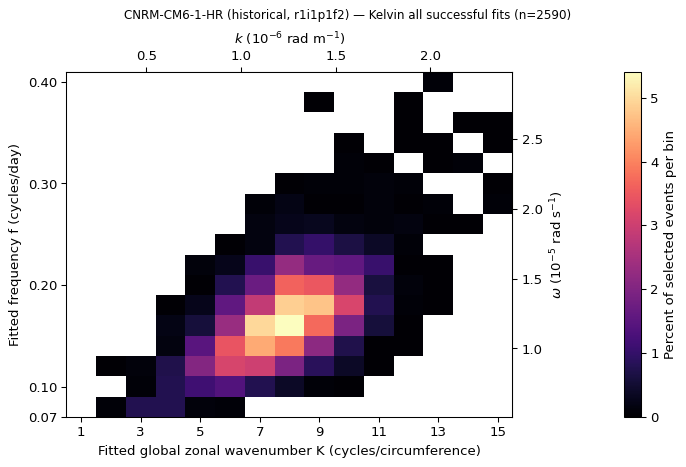

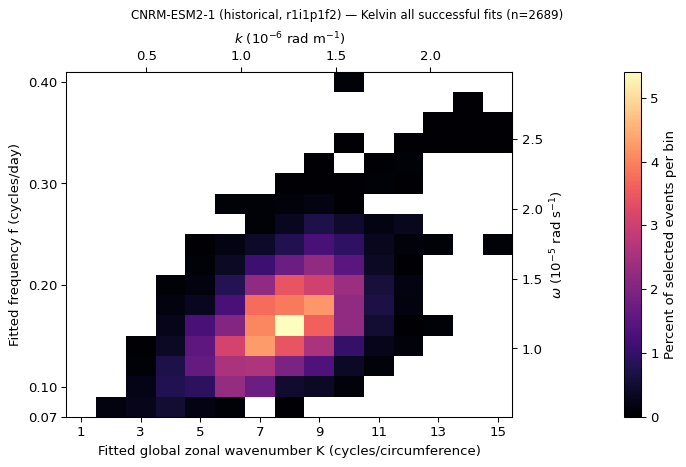

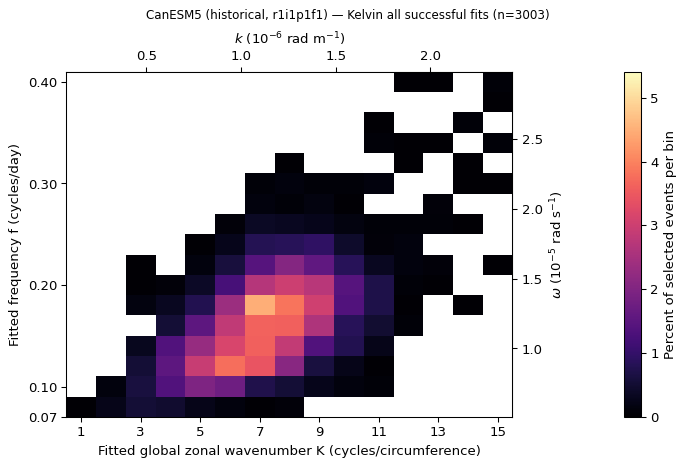

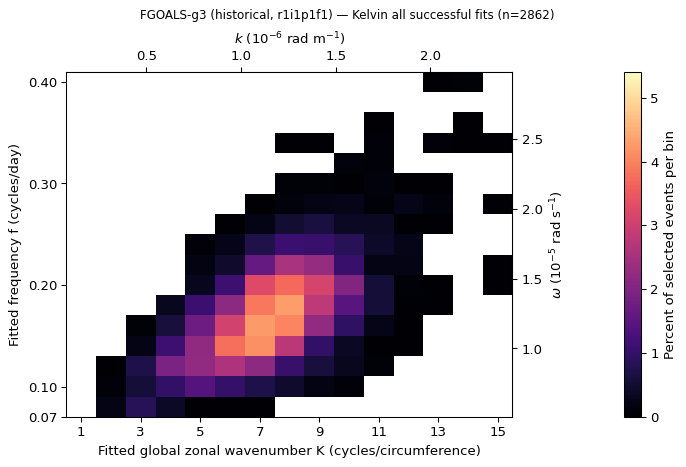

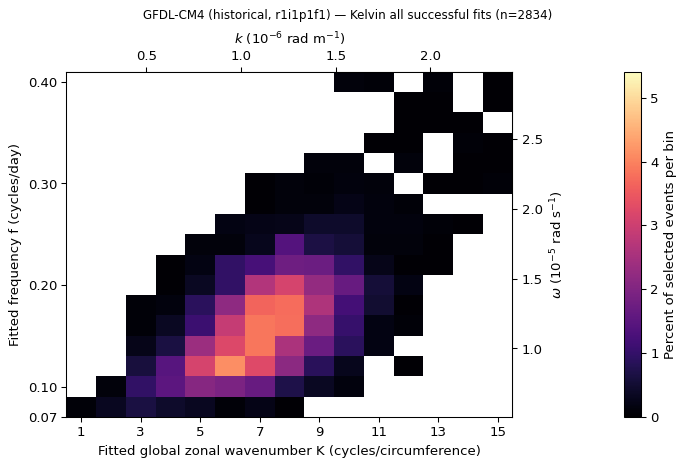

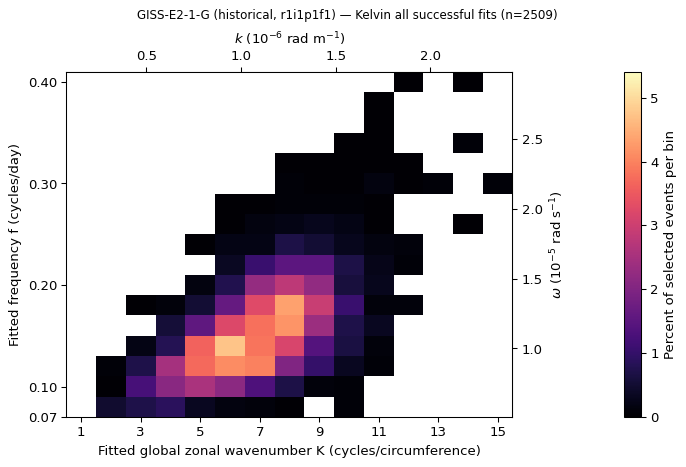

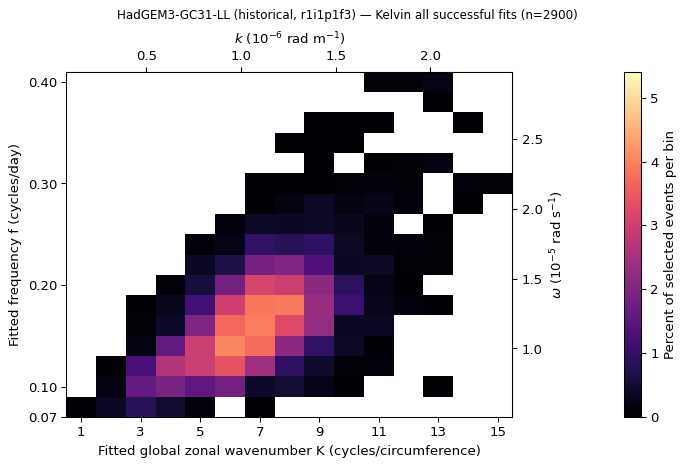

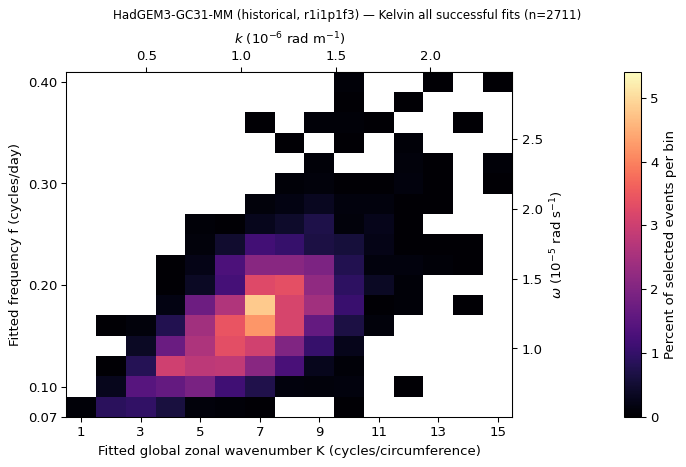

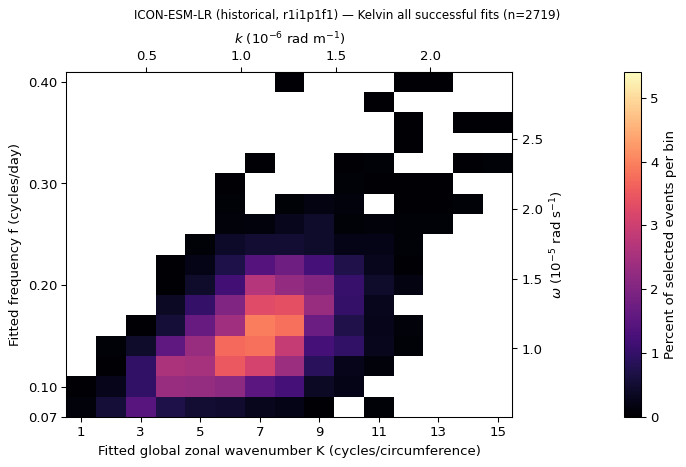

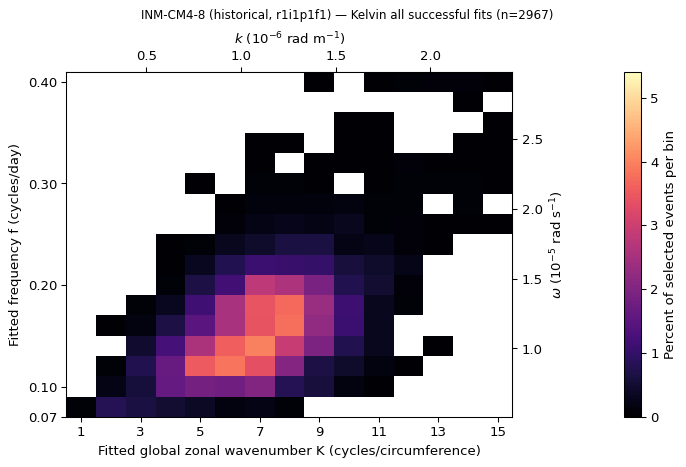

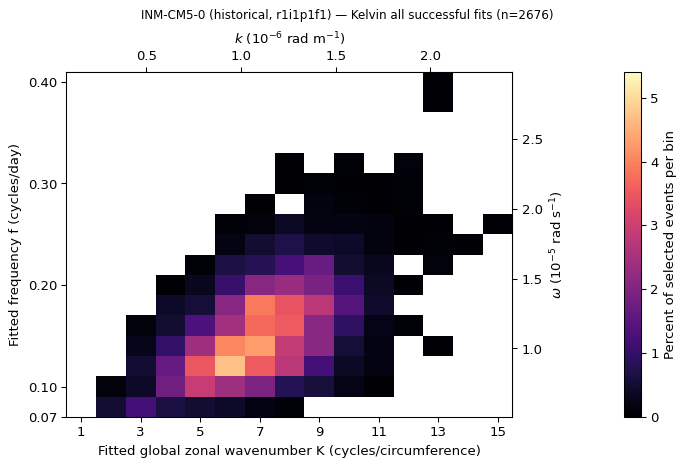

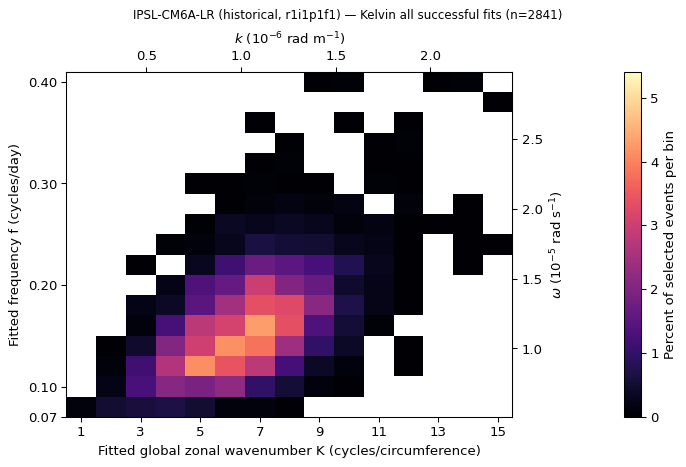

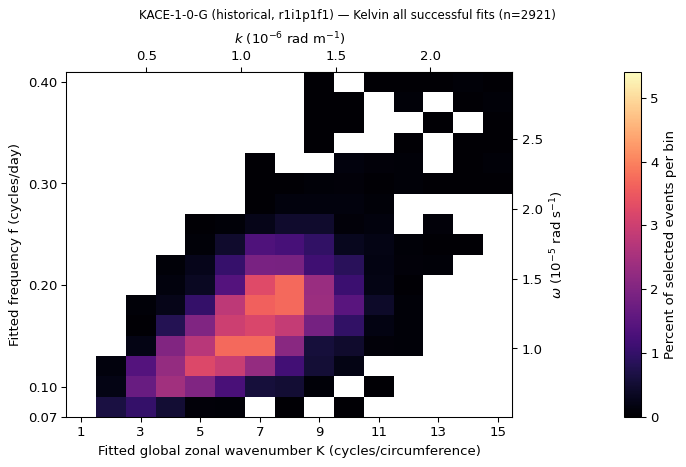

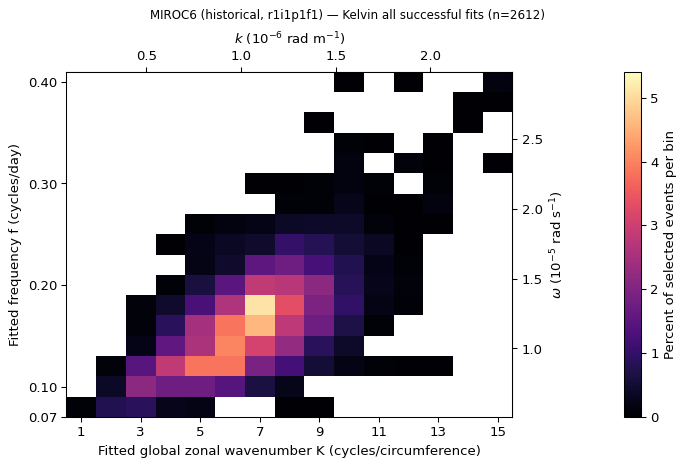

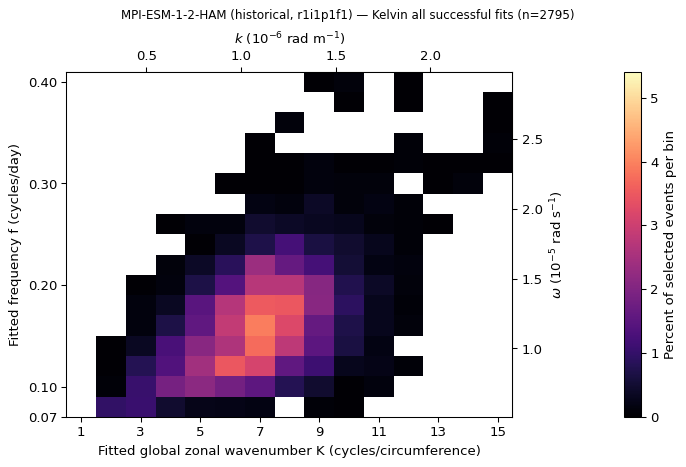

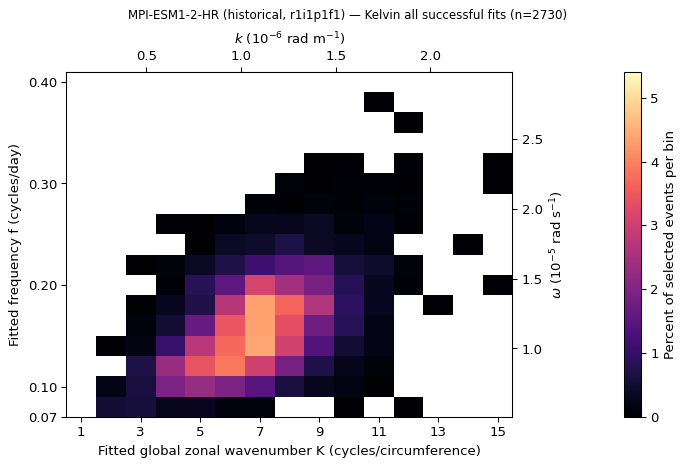

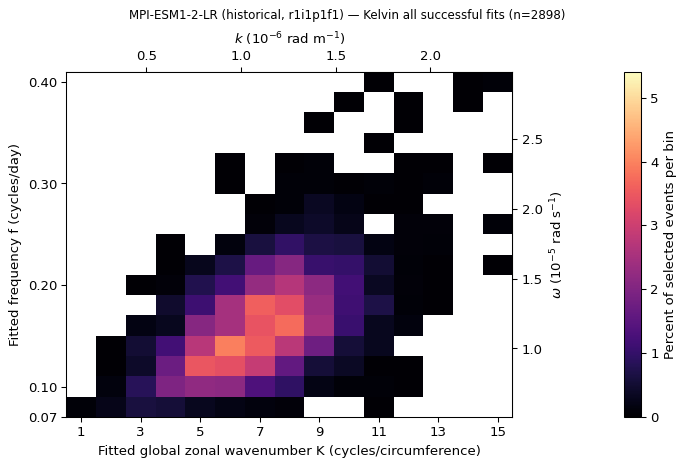

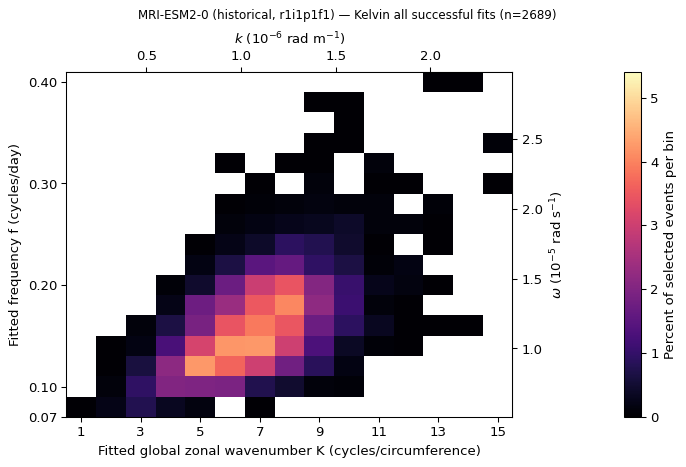

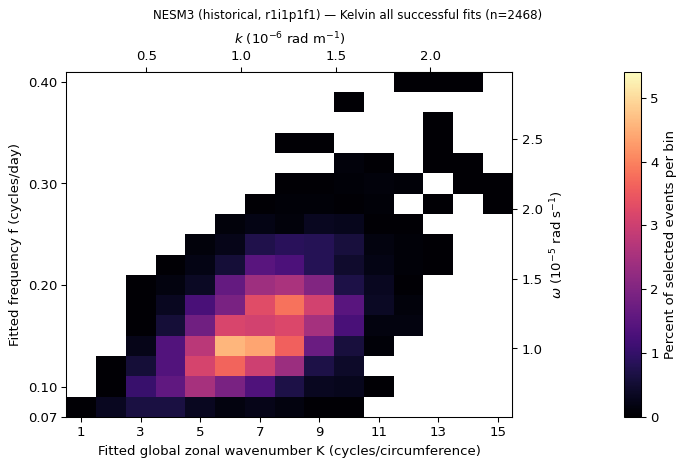

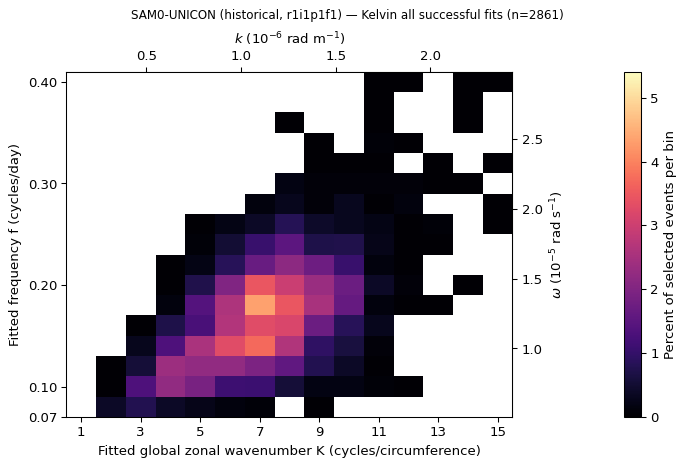

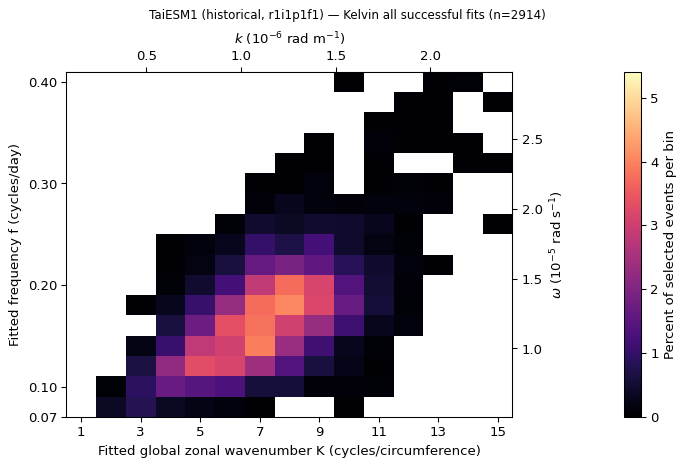

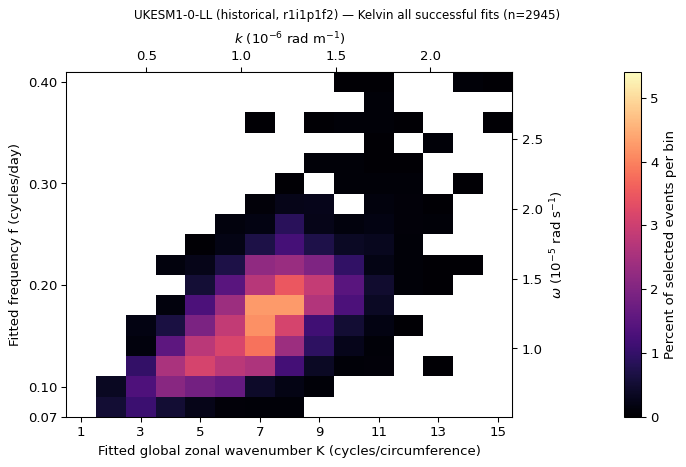

In [4]:
plot_records("fit_success", "historical")

### AMIP models (25 records)

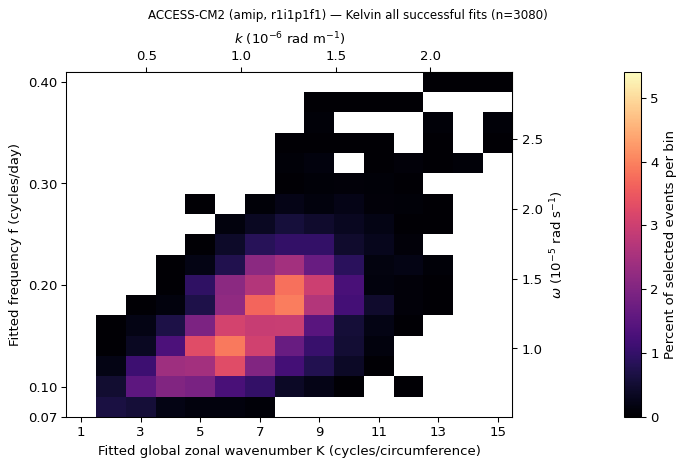

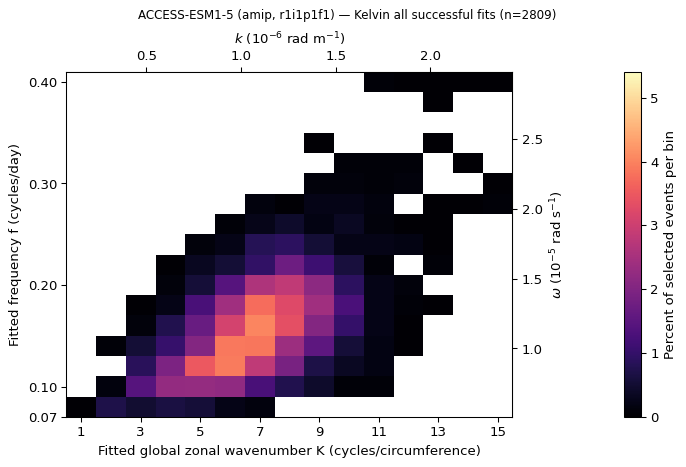

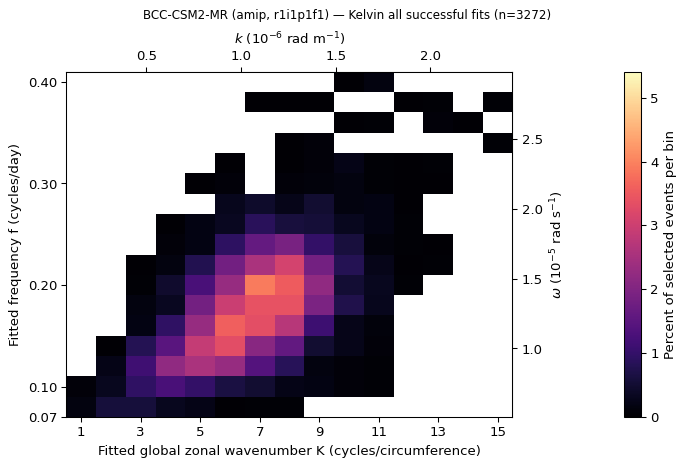

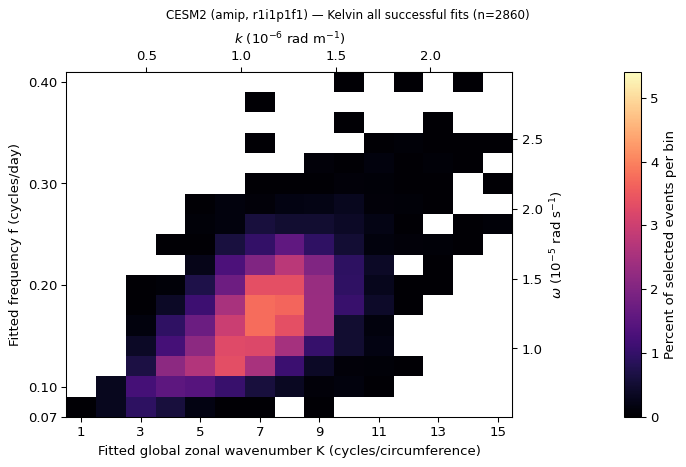

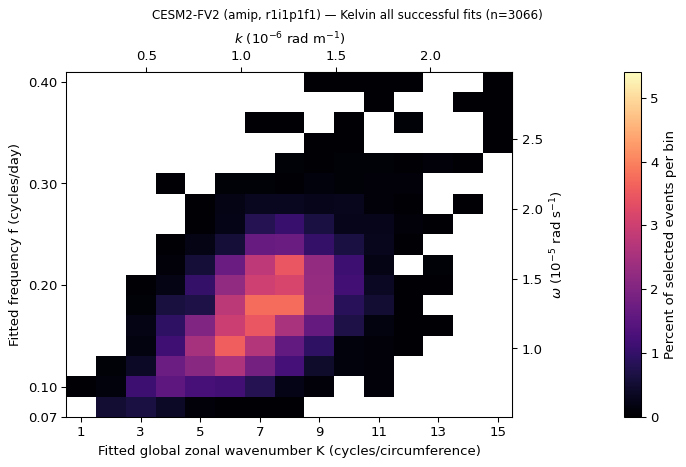

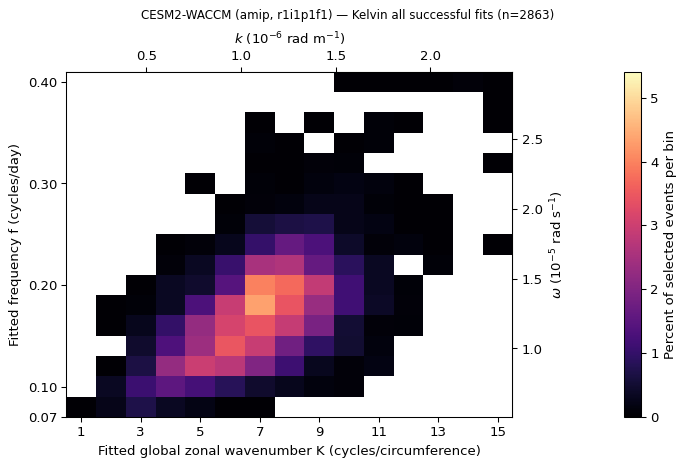

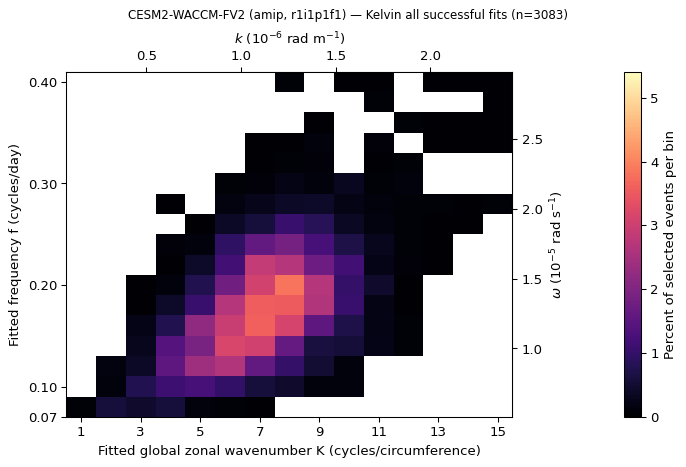

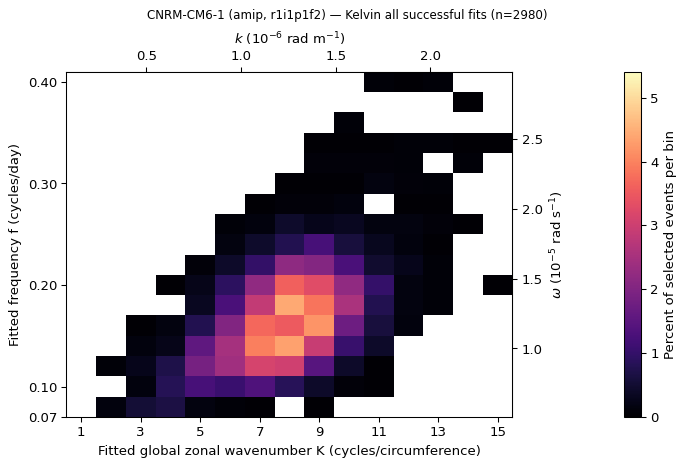

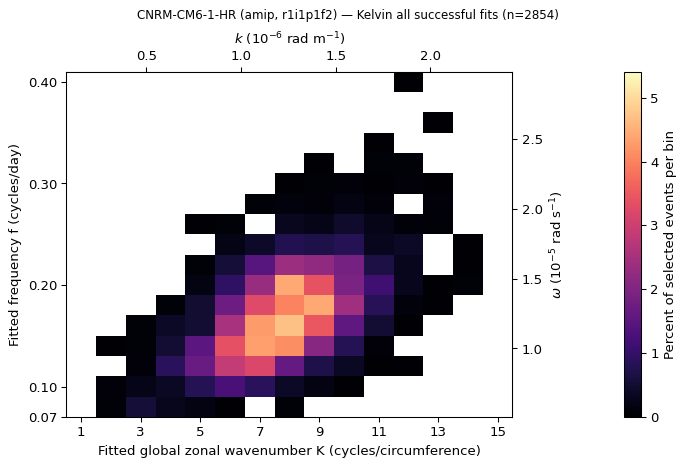

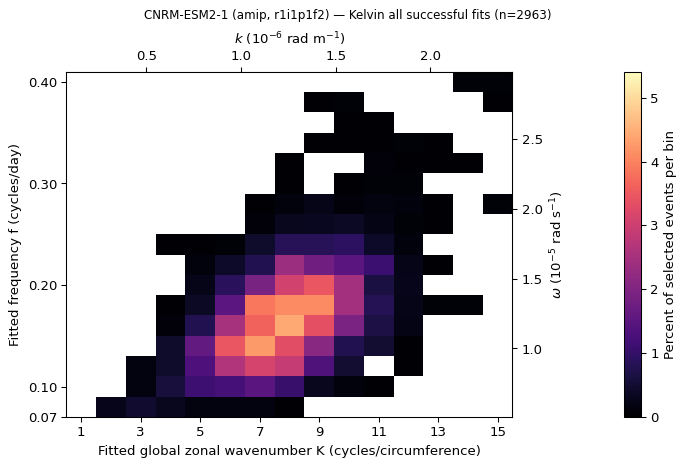

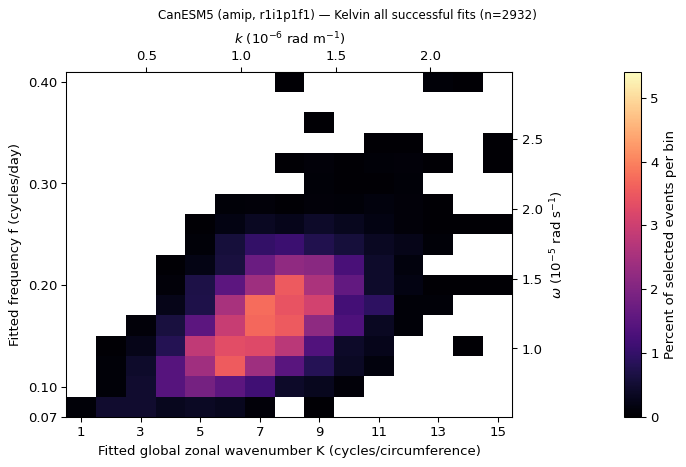

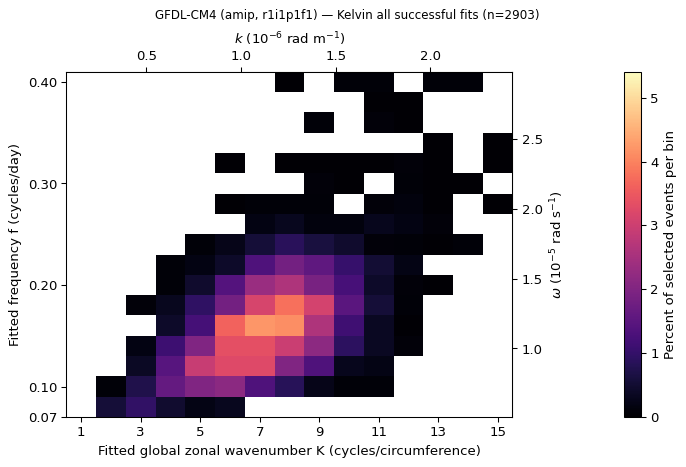

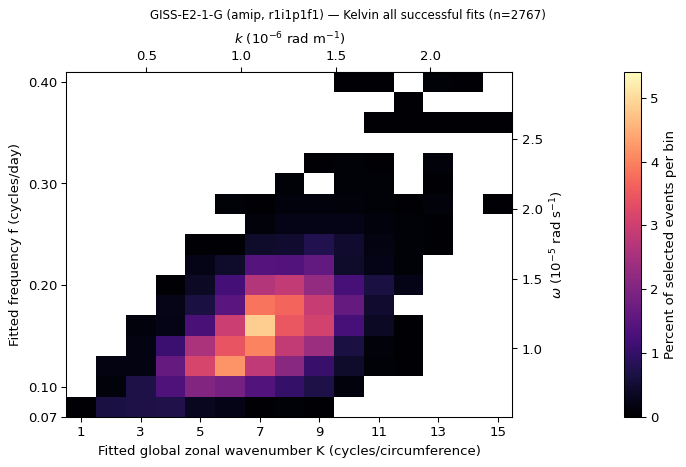

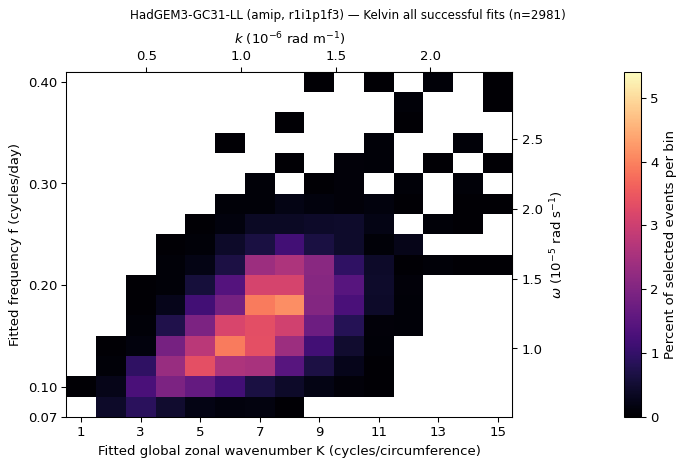

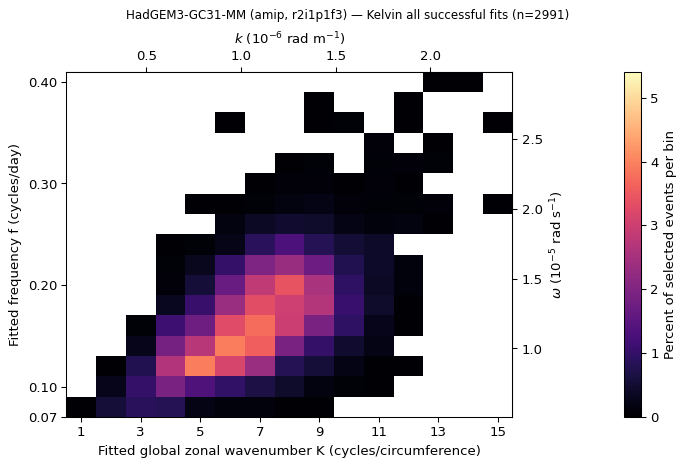

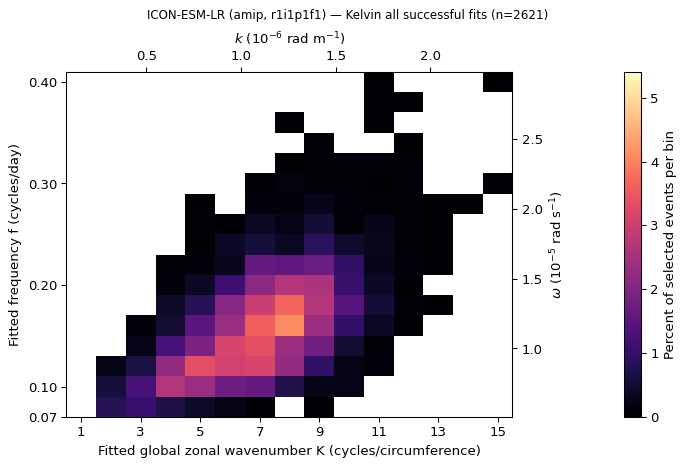

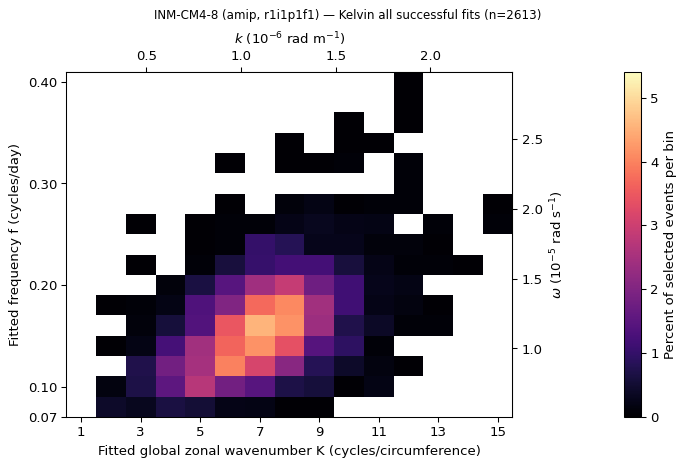

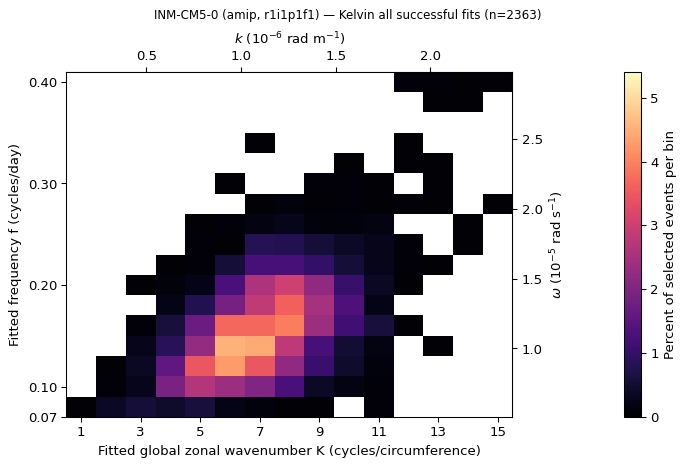

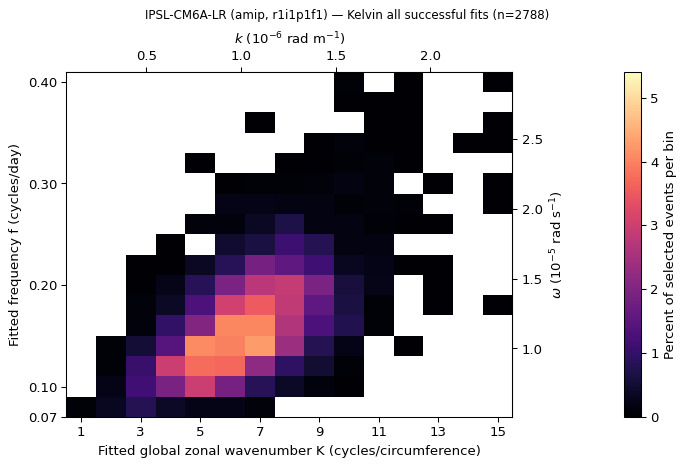

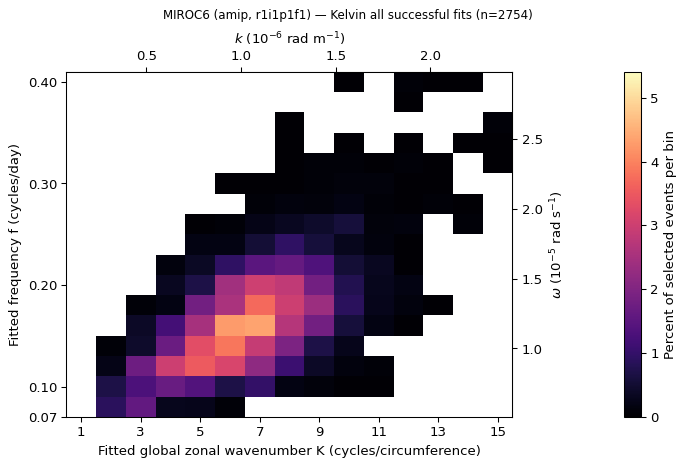

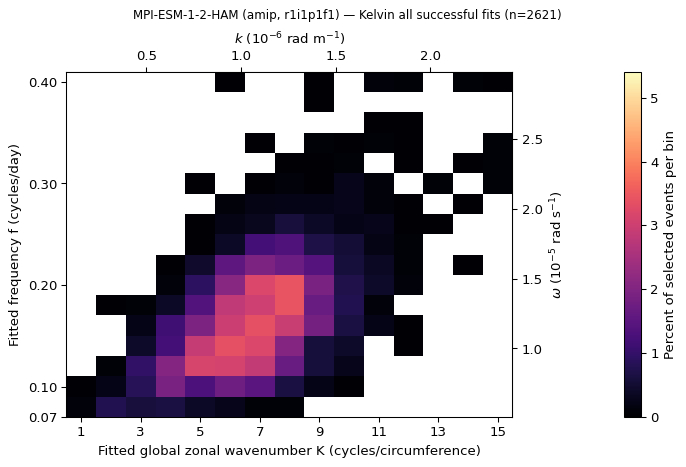

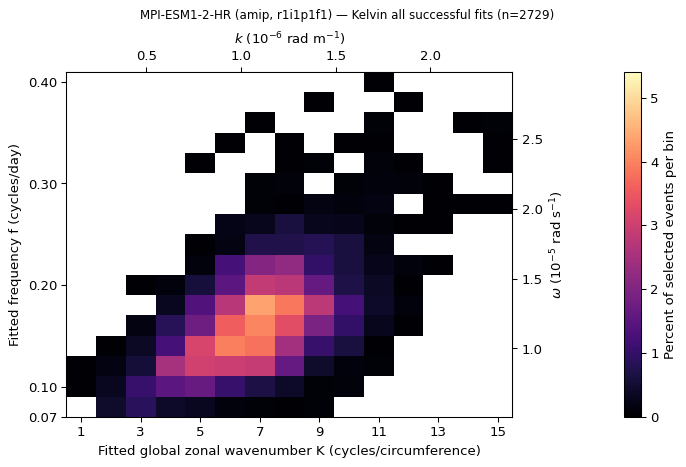

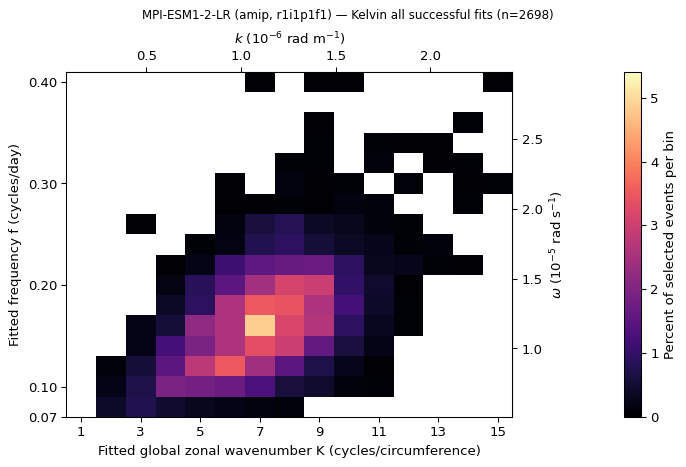

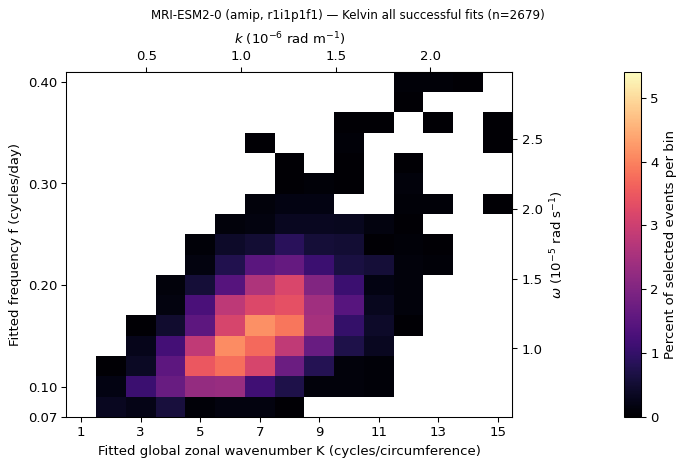

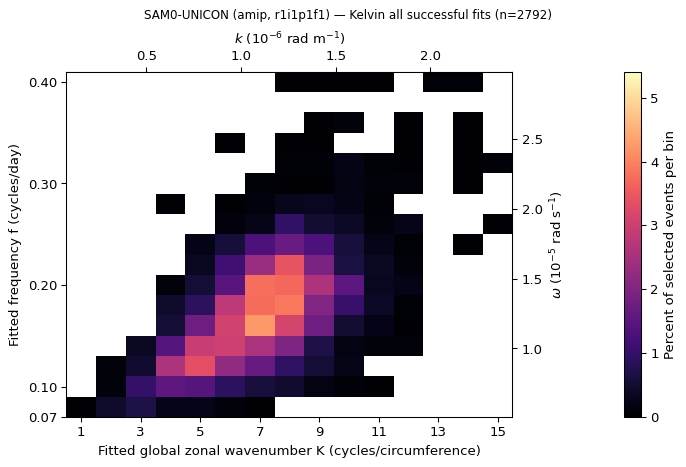

In [5]:
plot_records("fit_success", "amip")

## Quality-screened fits

The same catalogs and bins are used, now retaining only `keep_for_histogram` events. This selection requires acceptable sinusoid fit quality and adequate spatial/temporal cycle coverage; it is **not** a 1% amplitude-significance criterion. Its common color limit is set separately from the all-fit section because fewer events are retained.

### NOAA observations

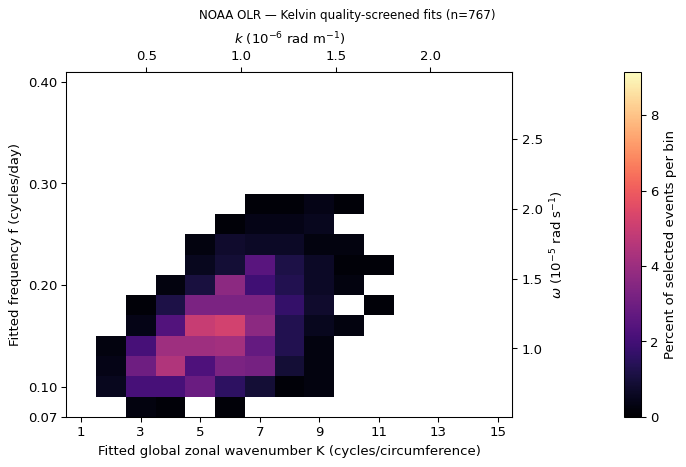

In [6]:
plot_records("keep_for_histogram", "observations")

### Historical models (34 records)

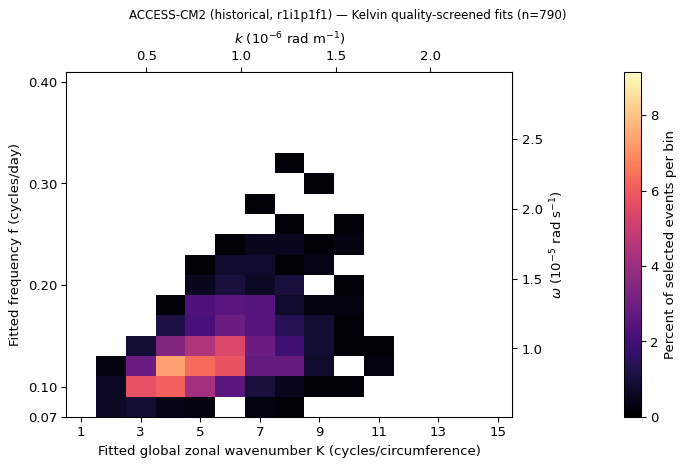

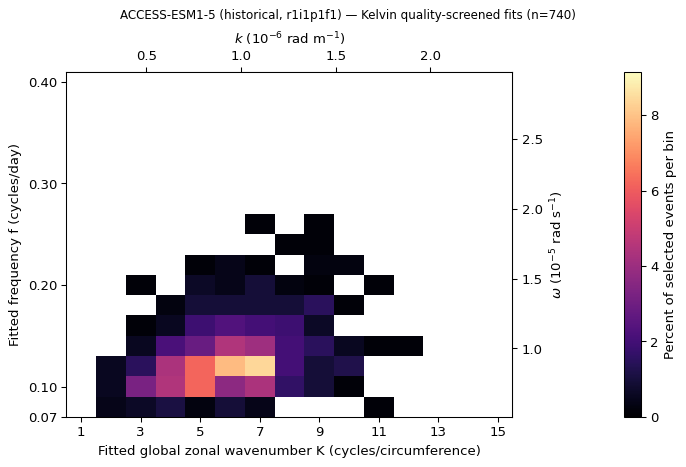

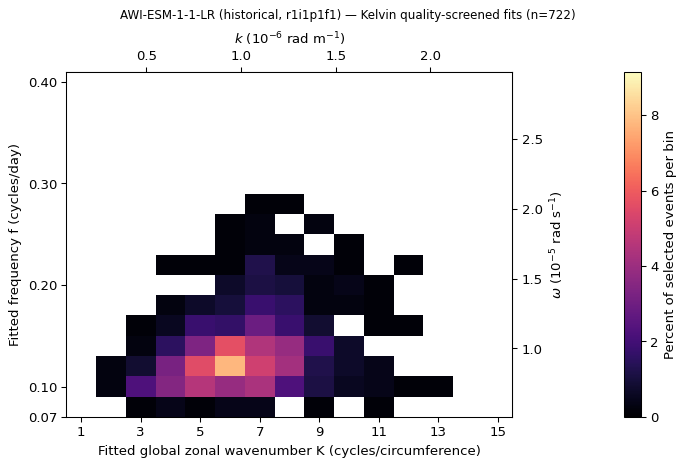

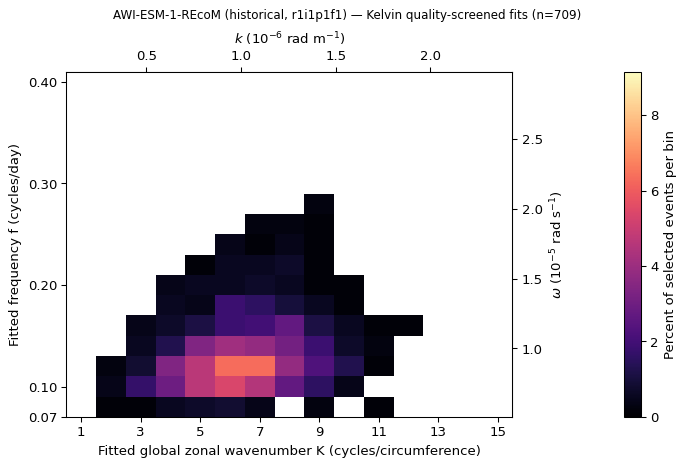

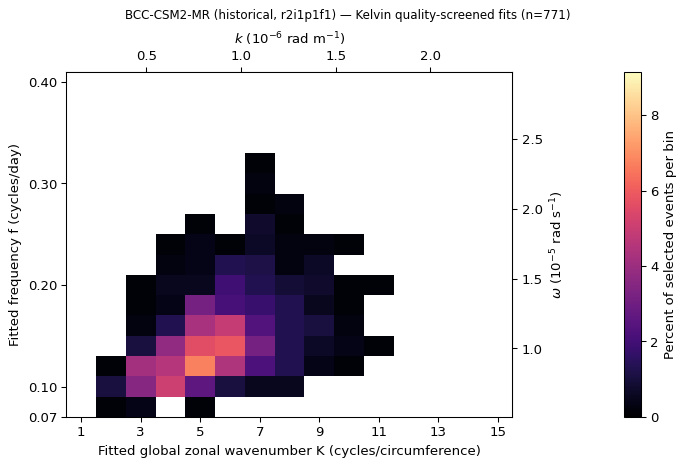

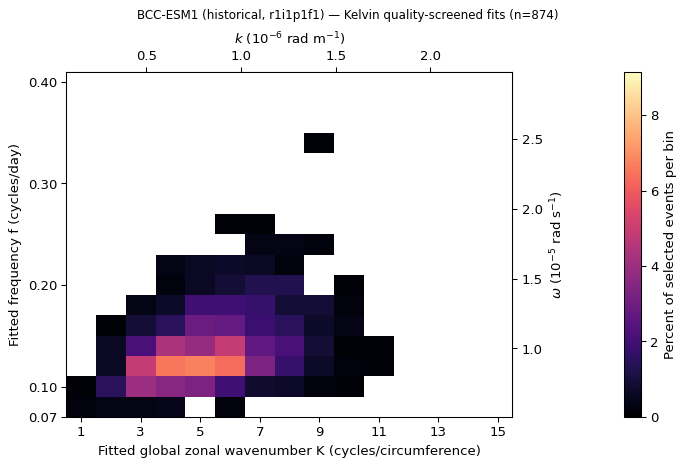

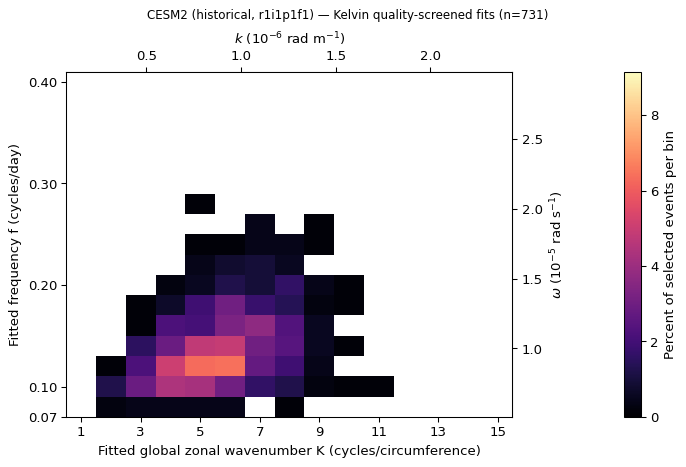

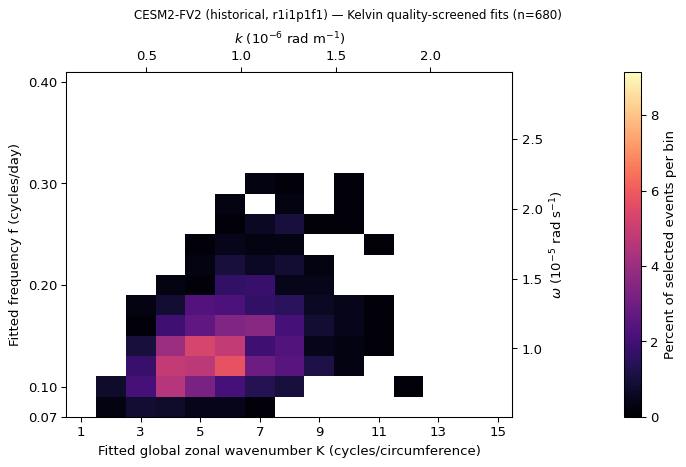

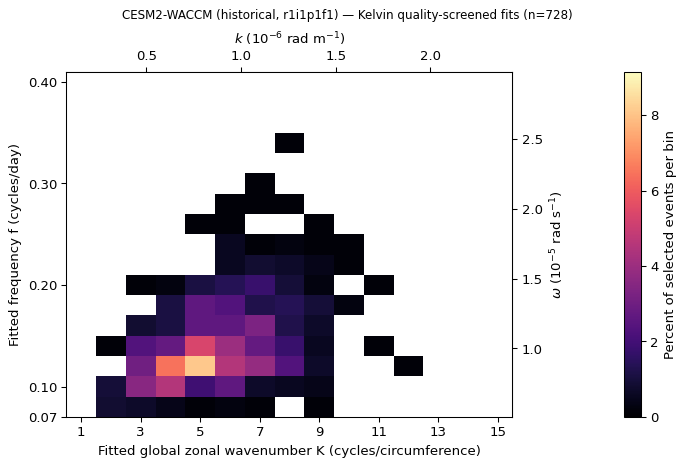

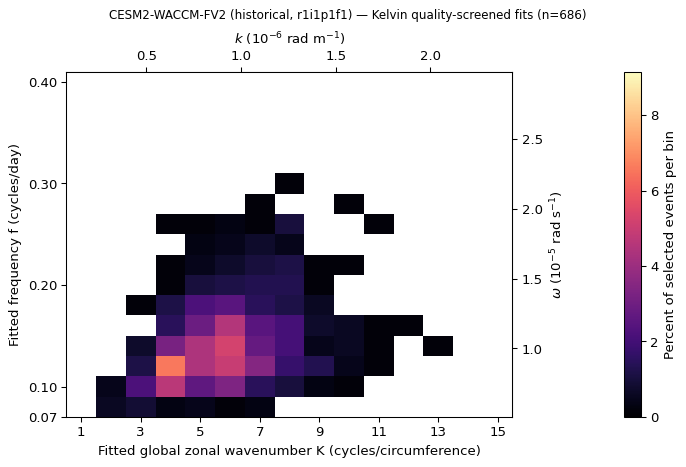

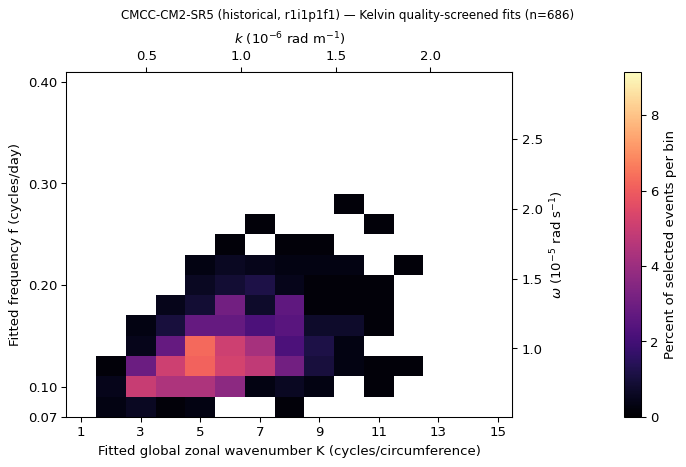

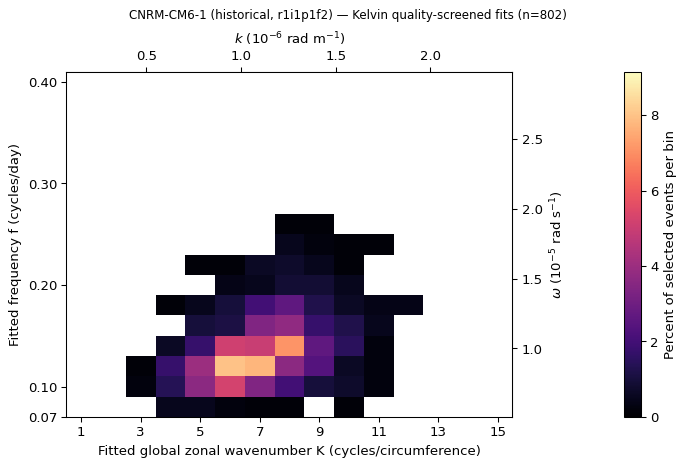

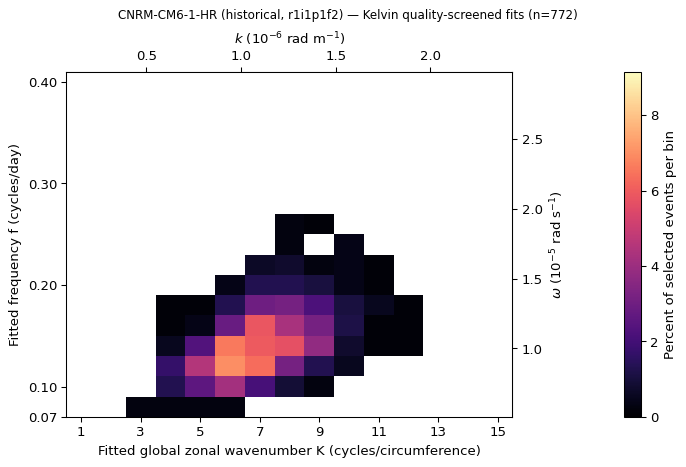

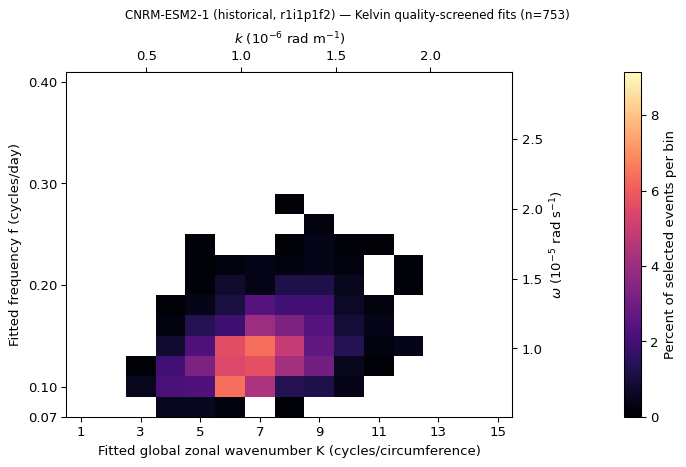

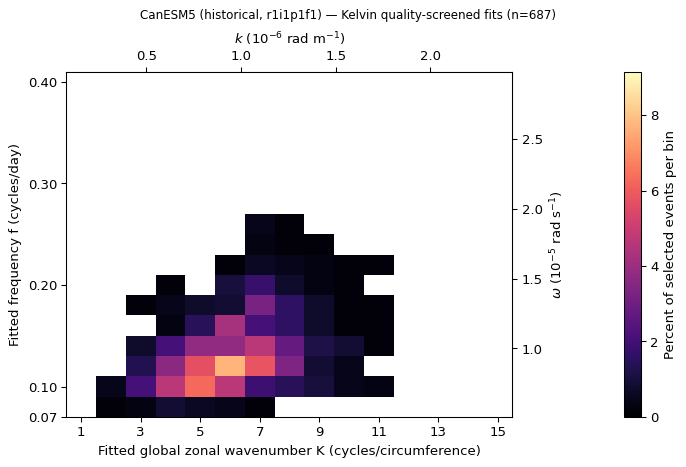

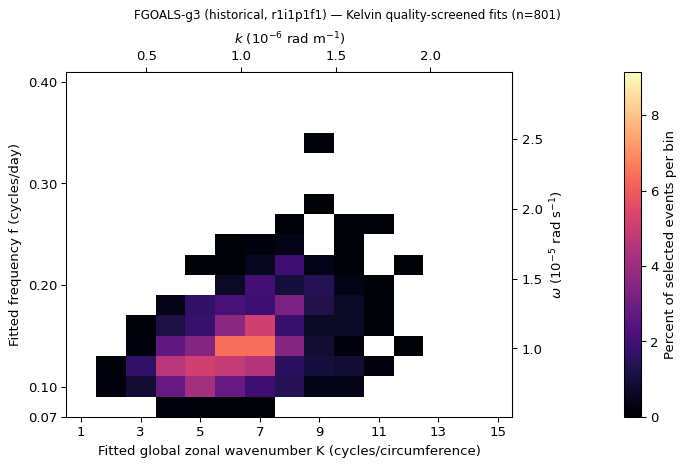

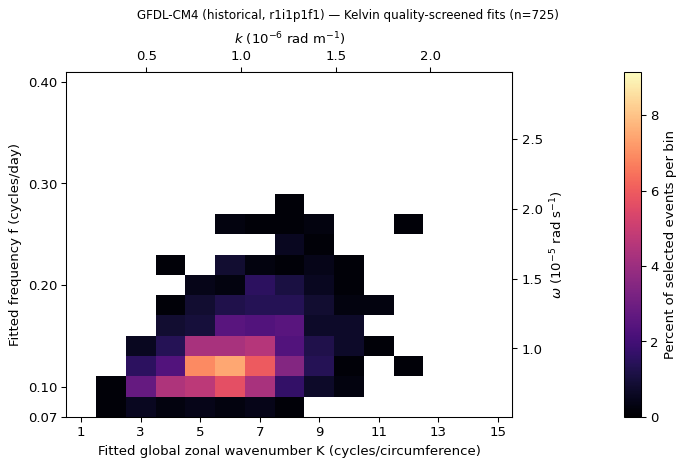

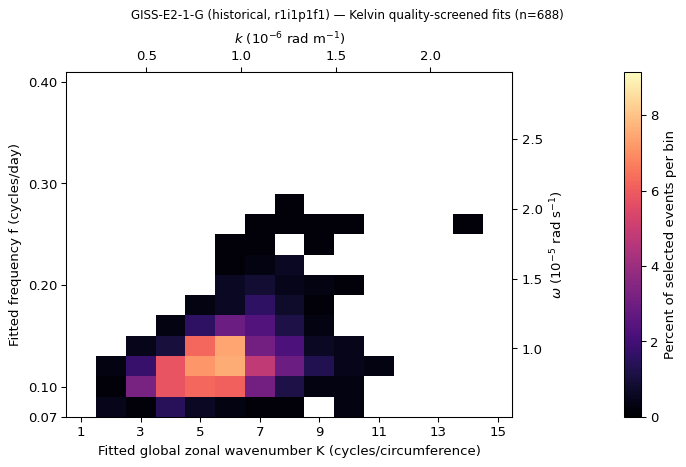

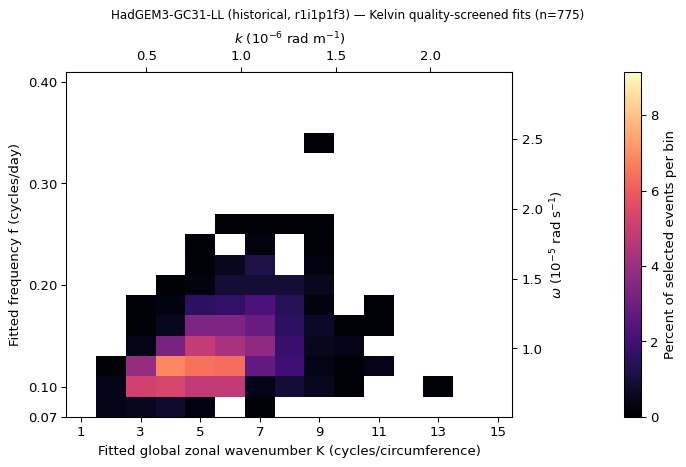

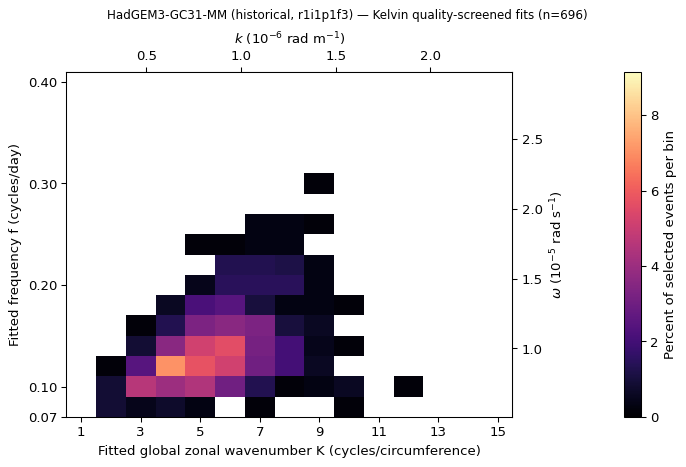

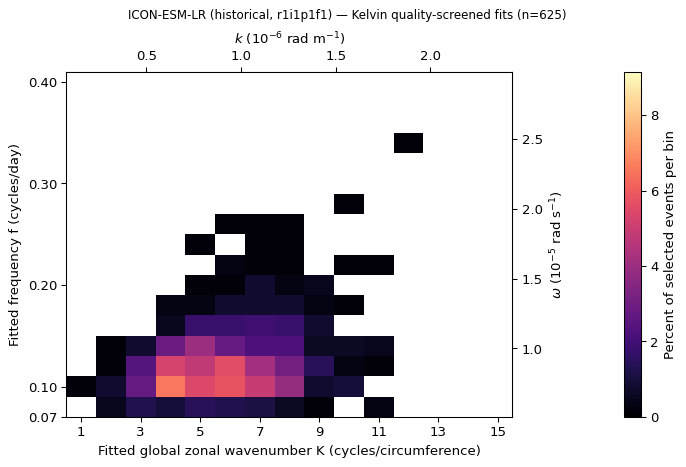

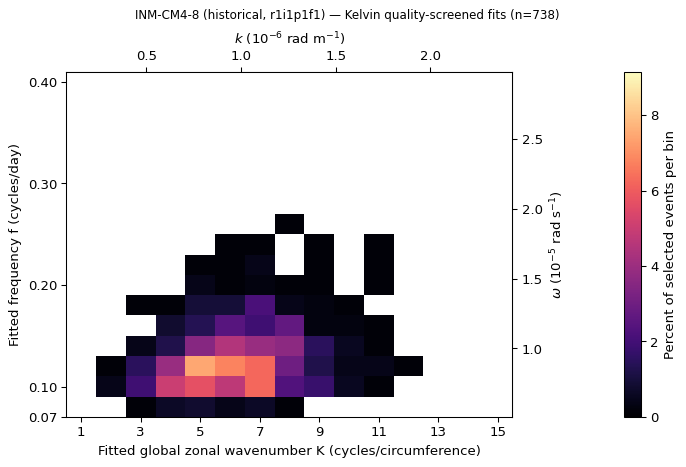

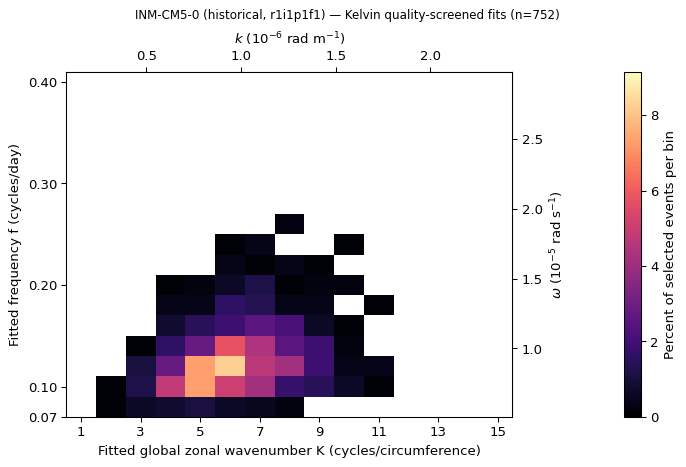

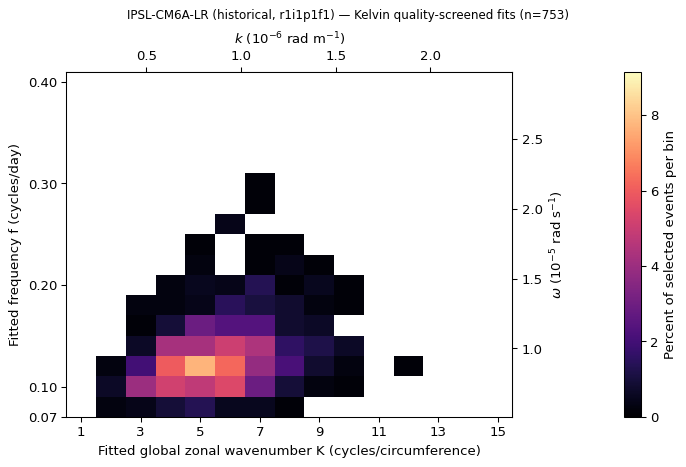

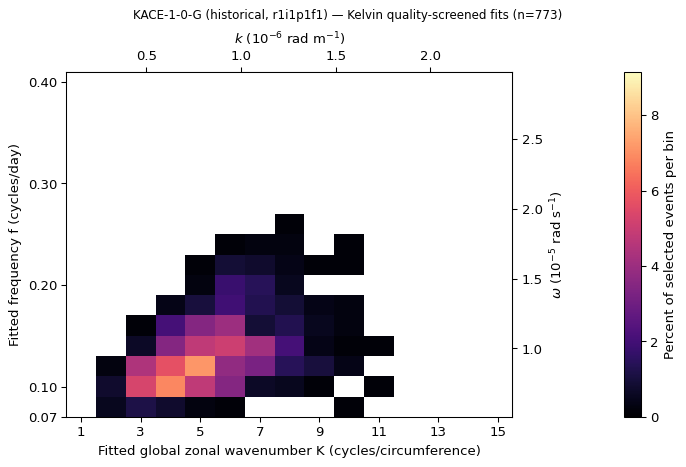

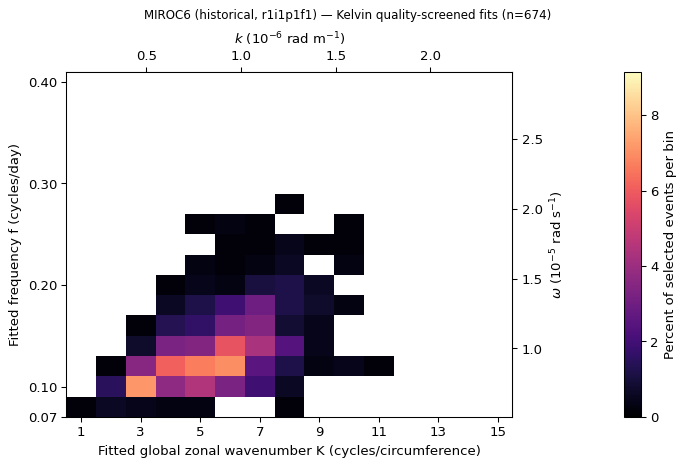

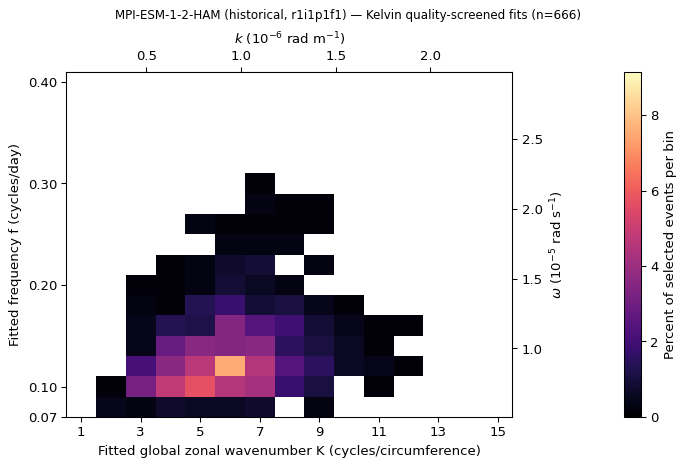

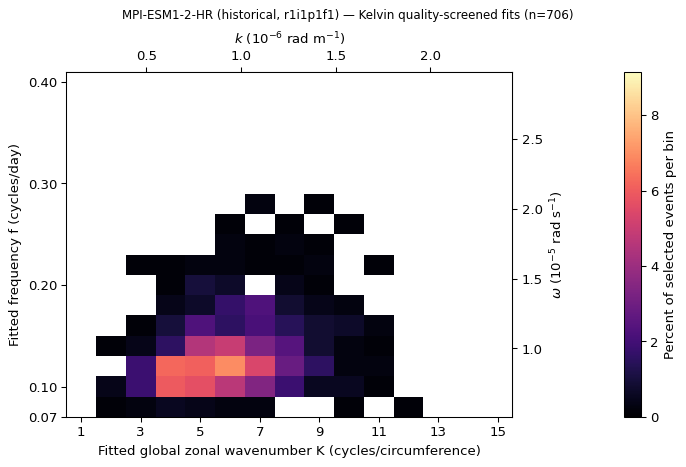

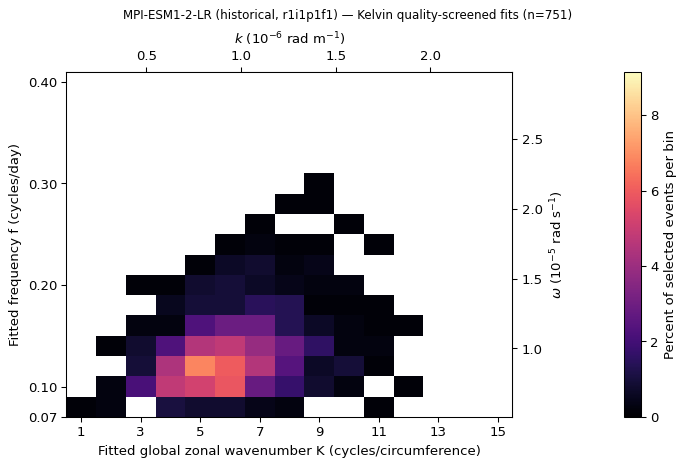

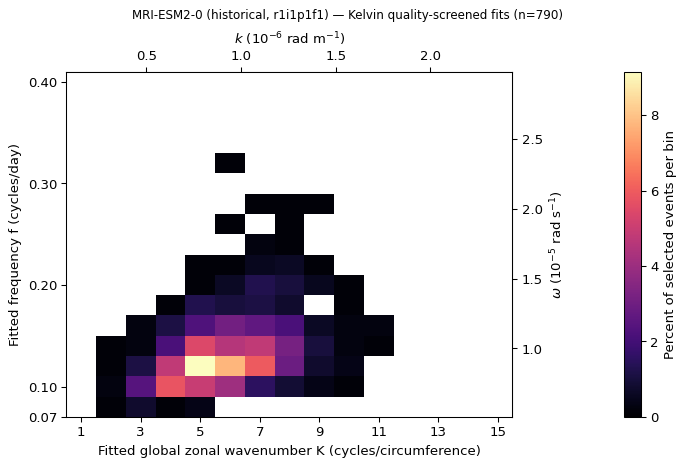

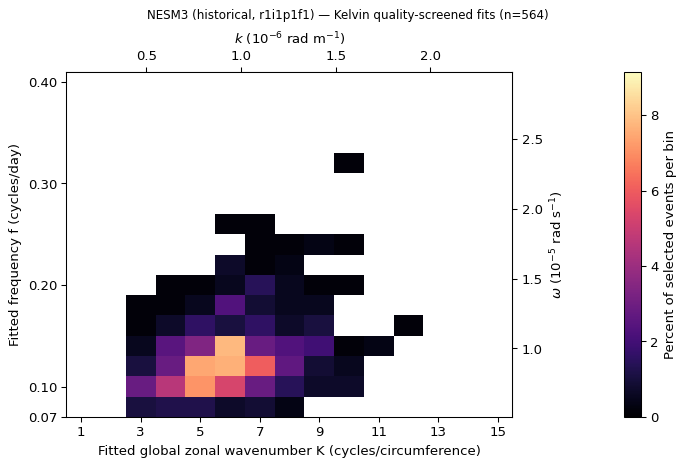

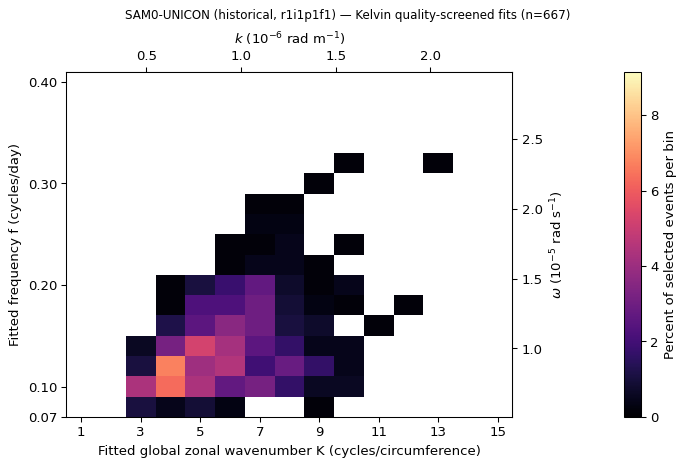

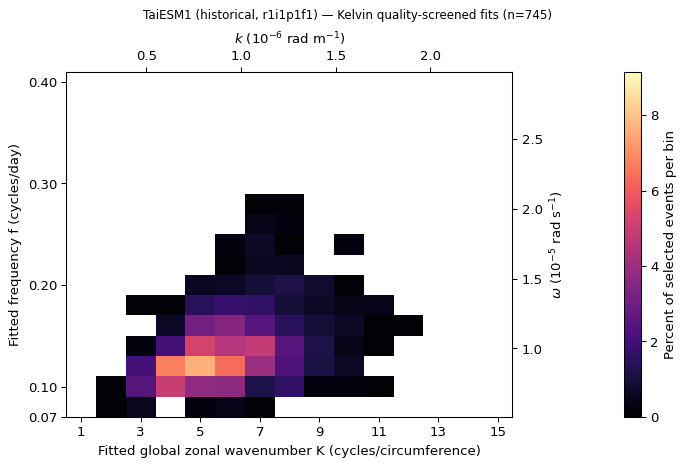

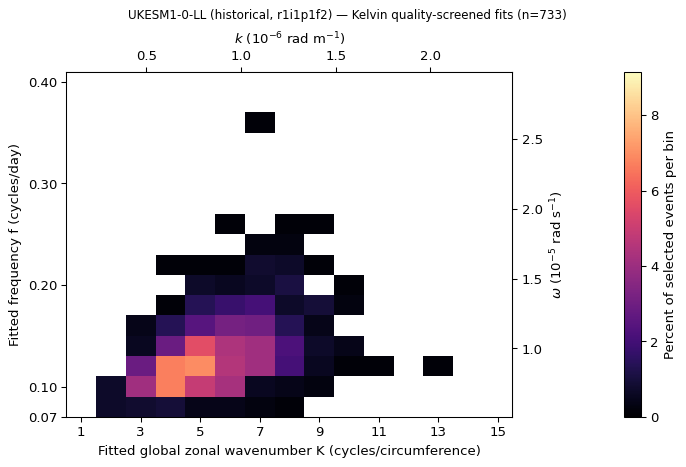

In [7]:
plot_records("keep_for_histogram", "historical")

### AMIP models (25 records)

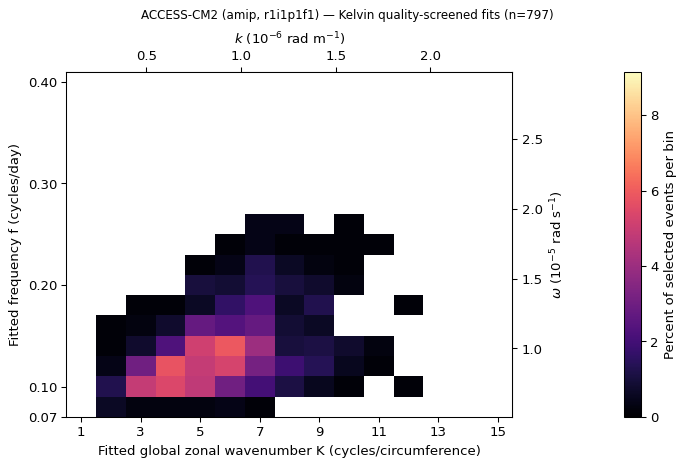

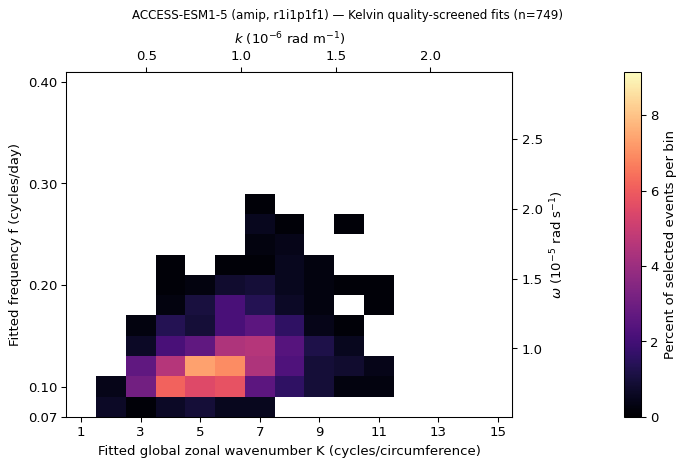

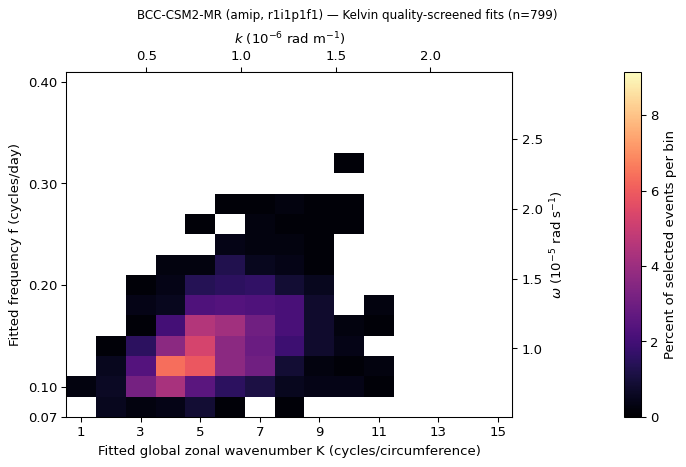

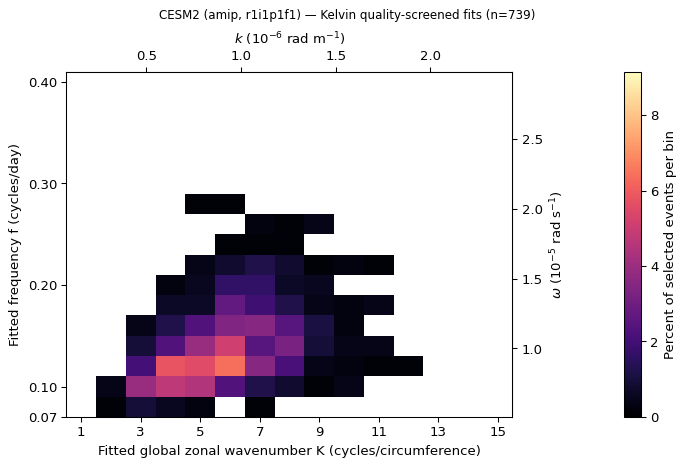

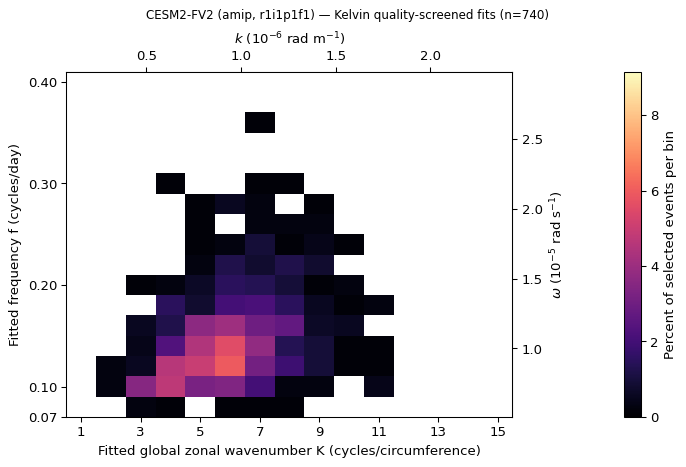

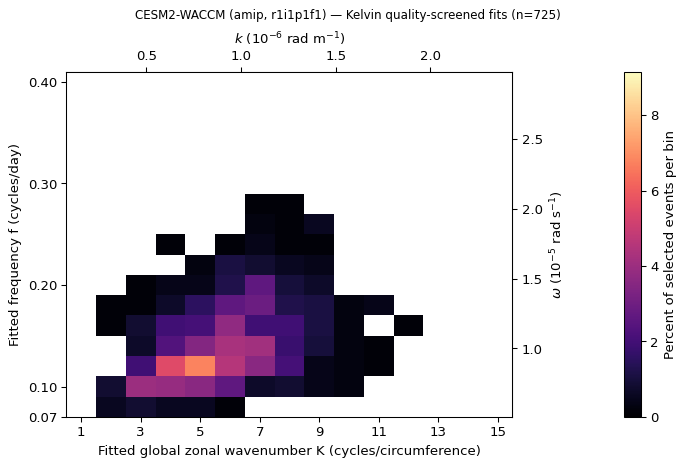

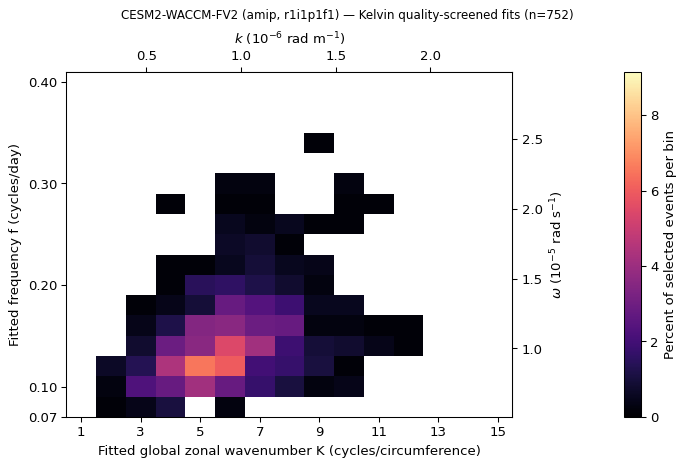

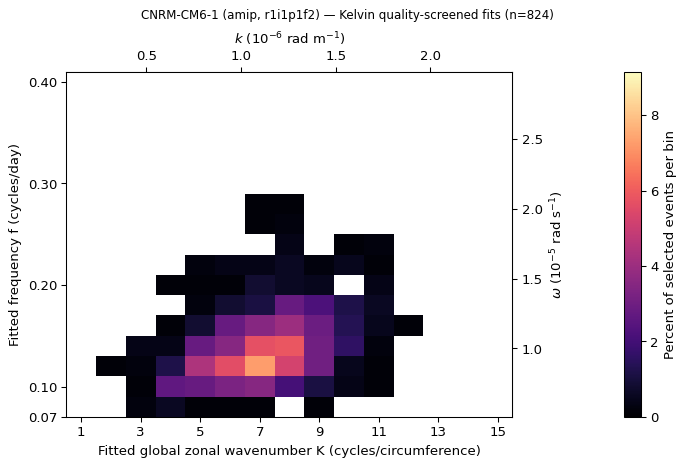

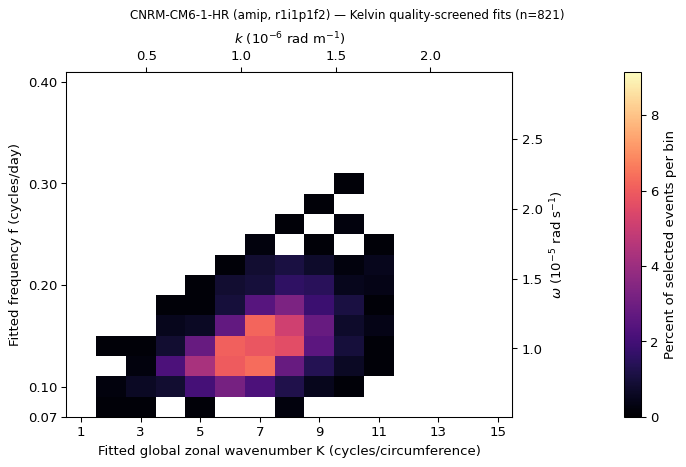

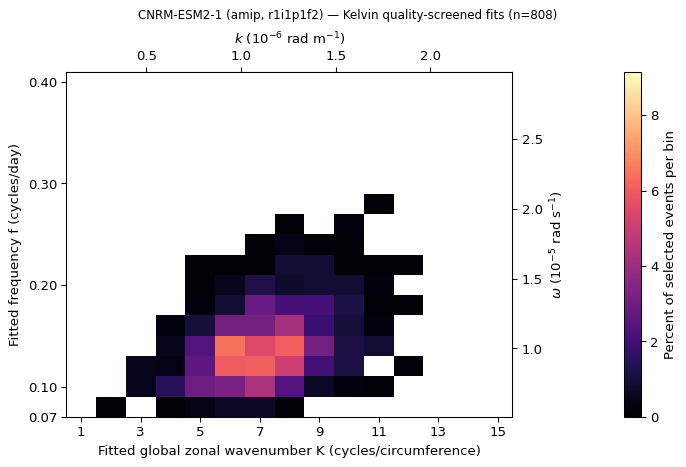

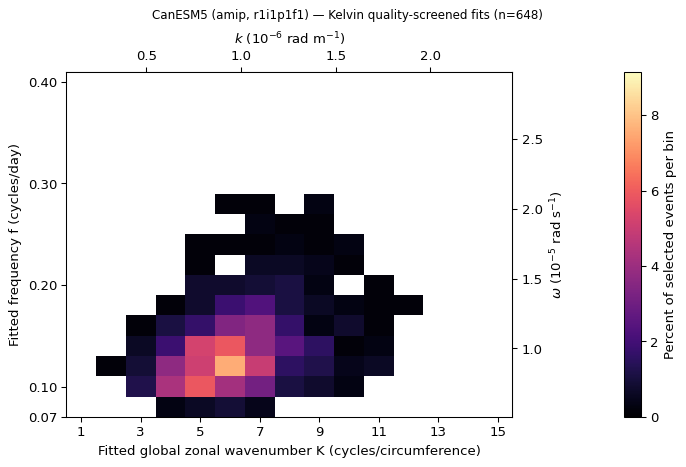

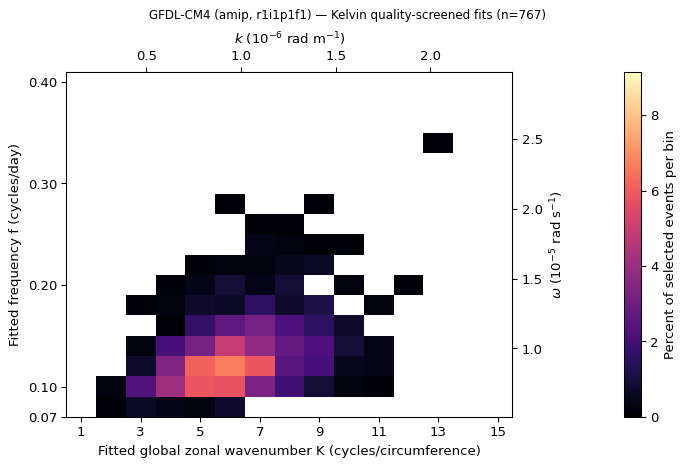

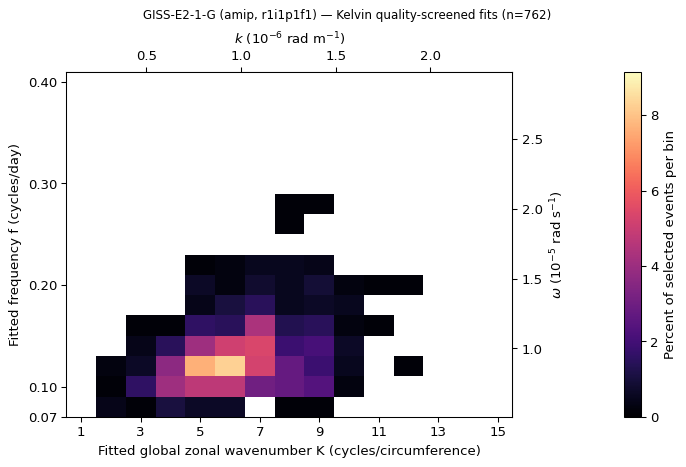

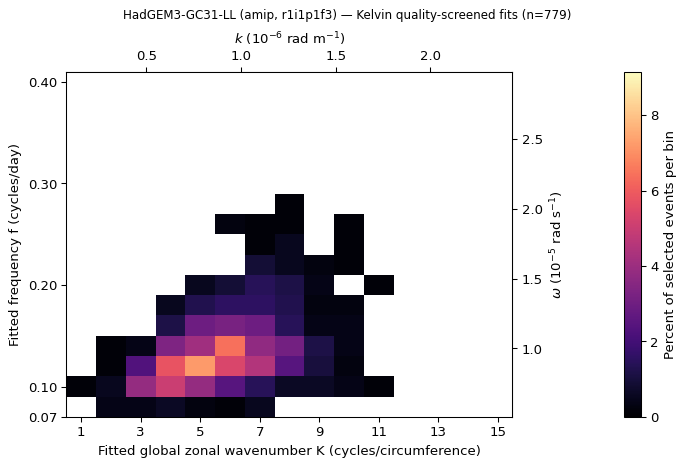

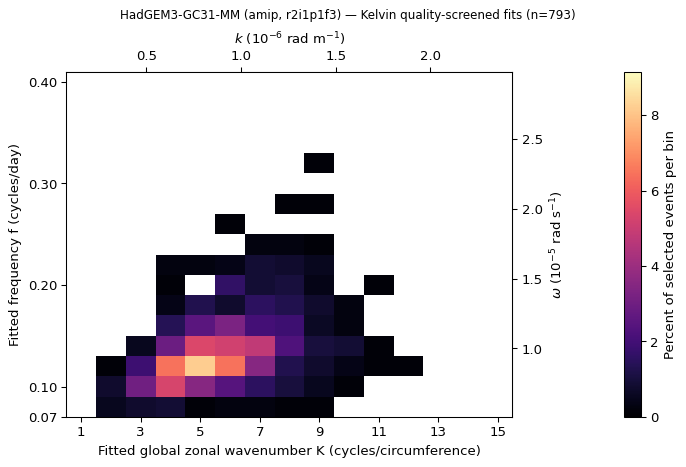

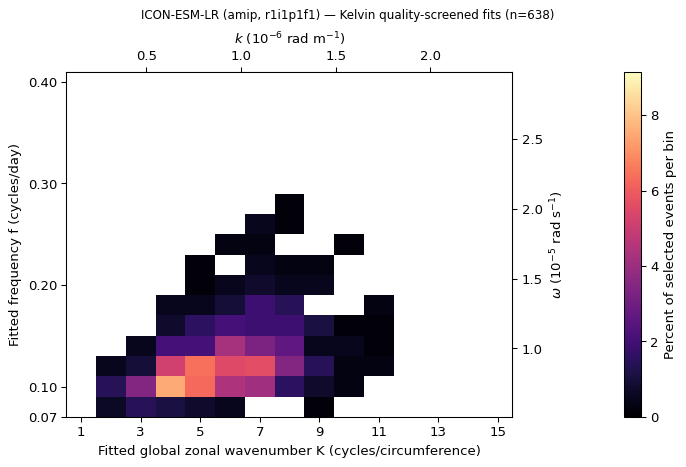

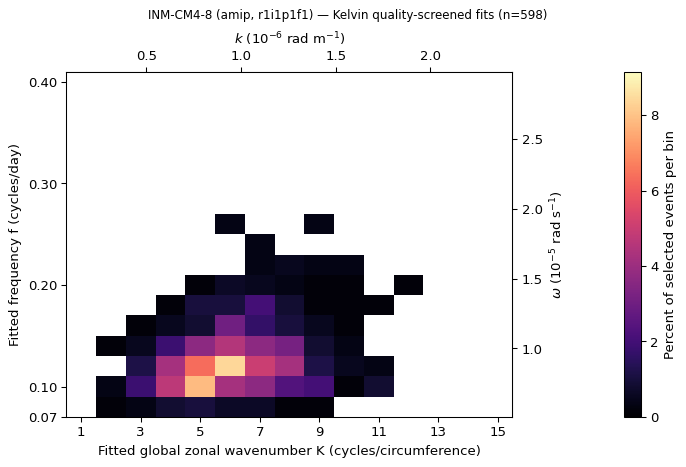

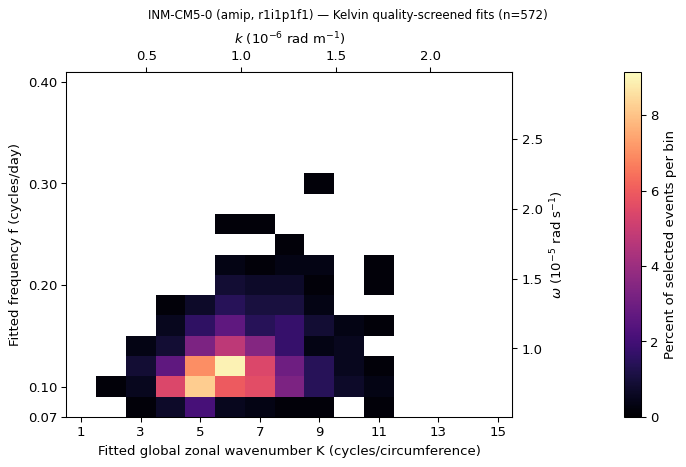

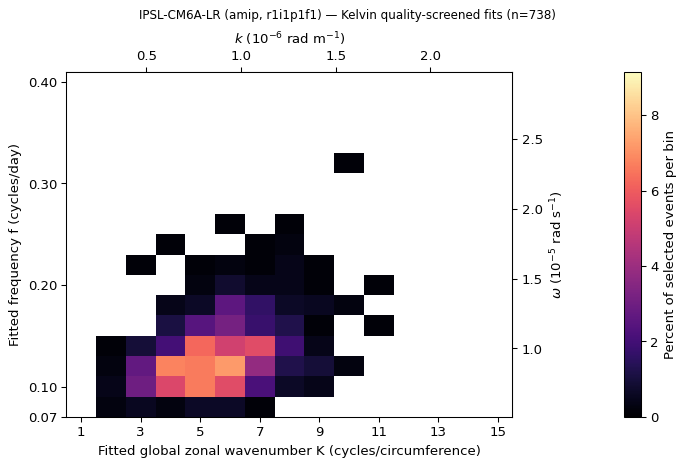

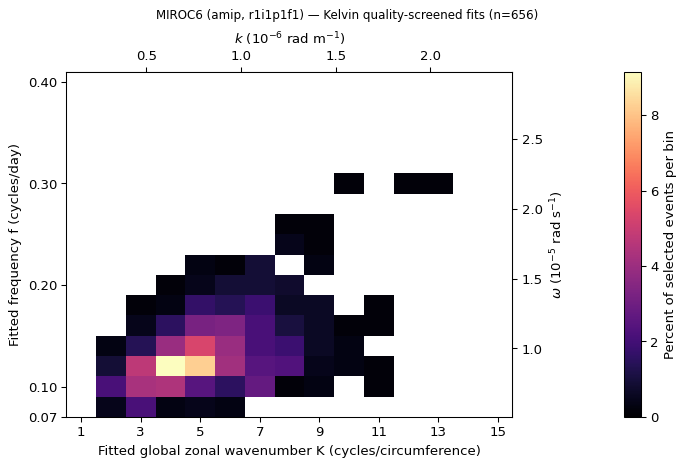

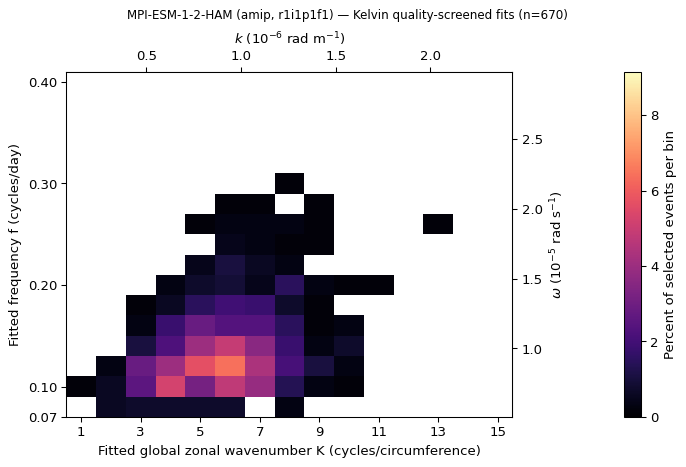

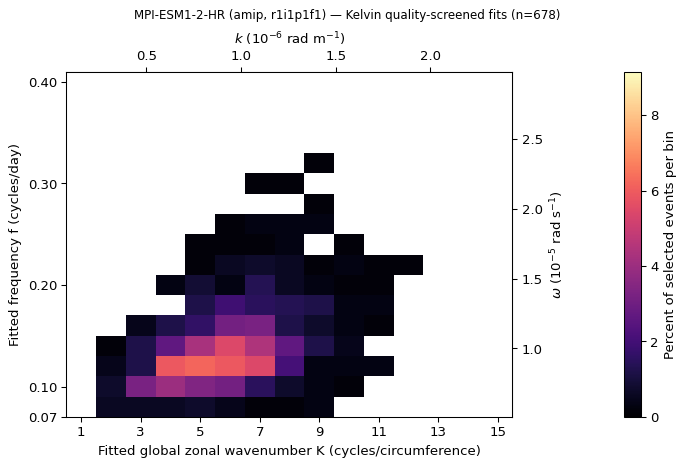

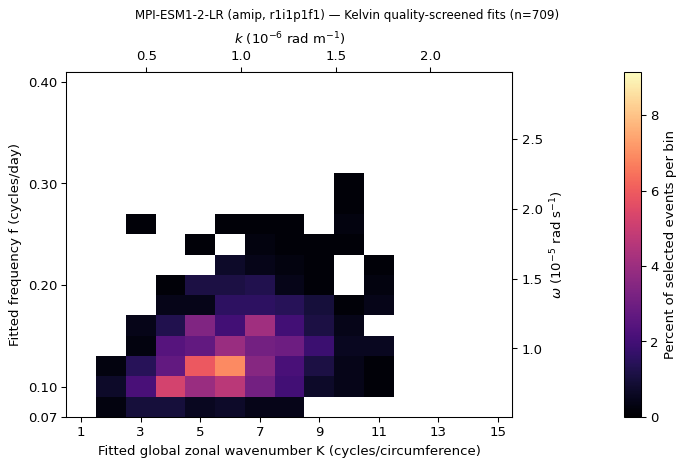

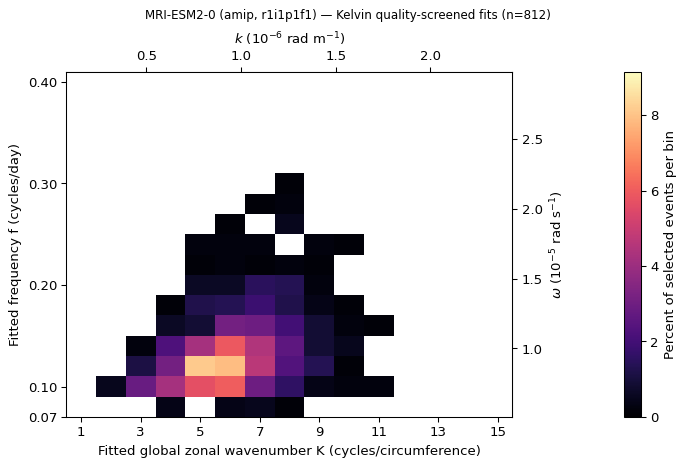

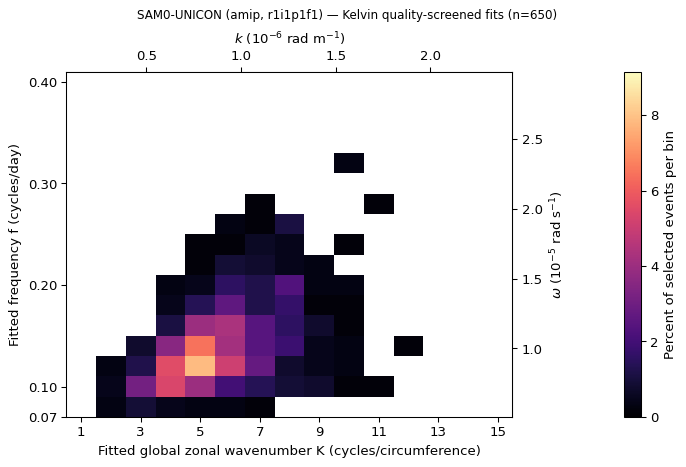

In [8]:
plot_records("keep_for_histogram", "amip")

## Per-record mean fitted coordinates

These event-weighted means summarize where each record lies within the common Kelvin fit box. Model ranges are across model/experiment records, not uncertainty intervals. The mean is sensitive to the population of detected events and is separate from the modal 2D bin.

In [9]:
summary = []
for selection in ("fit_success", "keep_for_histogram"):
    locations = (events.loc[events[selection].fillna(False)]
                 .groupby(IDENTITY)
                 .agg(mean_K=("K_global", "mean"), mean_f_cpd=("frequency_cpd", "mean"))
                 .reset_index())
    noaa_f = locations.loc[locations.experiment.eq("observations"), "mean_f_cpd"].iloc[0]
    for experiment in ("observations", "historical", "amip"):
        group = locations.loc[locations.experiment.eq(experiment)]
        summary.append({
            "selection": selection, "experiment": experiment, "records": len(group),
            "median_mean_K": group.mean_K.median(),
            "range_mean_K": f"{group.mean_K.min():.3f}–{group.mean_K.max():.3f}",
            "median_mean_f_cpd": group.mean_f_cpd.median(),
            "range_mean_f_cpd": f"{group.mean_f_cpd.min():.3f}–{group.mean_f_cpd.max():.3f}",
            "records_with_mean_f_at_or_above_NOAA": int((group.mean_f_cpd >= noaa_f).sum()),
        })
display(pd.DataFrame(summary).round(3))

,selection,experiment,records,median_mean_K,range_mean_K,median_mean_f_cpd,range_mean_f_cpd,records_with_mean_f_at_or_above_NOAA
0,fit_success,observations,1,6.977,6.977–6.977,0.182,0.182–0.182,1
1,fit_success,historical,34,7.002,6.502–7.816,0.164,0.154–0.181,0
2,fit_success,amip,25,7.023,6.567–7.876,0.166,0.157–0.178,0
3,keep_for_histogram,observations,1,5.811,5.811–5.811,0.157,0.157–0.157,1
4,keep_for_histogram,historical,34,5.925,5.414–7.088,0.135,0.124–0.147,0
5,keep_for_histogram,amip,25,5.949,5.305–7.175,0.136,0.126–0.147,0


## Interpretation limits

The plotted domain is the Kelvin **filter and fit search box**, so occupancy within it is conditional on that choice. Percentages describe the locations of detected fitted events, not Fourier power or the statistical significance of a spectral peak. Comparing screened and all-fit maps reveals how the fit-quality rule changes the apparent occupancy. The 59 model records include paired experiments for some models and one member each, so their spread is not an independent-sample uncertainty estimate.

In these 1990–2010 catalogs, NOAA has a higher event-mean fitted Kelvin frequency than every one of the 59 model/experiment records under both selections. This is a descriptive comparison within the shared Kelvin filter box, not a formal test or a diagnosis of why the models differ.
